### About task

In this assignment you:
- get familiar with what happens "inside" support vector machine and logistic regression
- get familiar with probability calibration
- learn variable transformation methods and feature selection methods
- try to evaluate the economic effect of the model

#### Deadline:

- Soft deadline 1-Mart-2024
- Hard deadline 8-Mart-2024


# Part 1. SVM, LR and probability calibration (2 points + 0.5 bonus)

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             roc_curve, auc)

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)

RANDOM_STATE = 42

#### Task 1.1. Compare the methods (0.5 points)


Let's generate synthetic data.

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(
    n_samples=10000, n_features=10, n_informative=5, n_redundant=5,
    random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

print(X_train.shape, X_test.shape, "positive share:", y.mean().round(3))

(7000, 10) (3000, 10) positive share: 0.5


__Random classifier__

First, let's define the simplest model, which produces a random answer for each object. Using the test sample, we calculate AUC-ROC, AUC-PR.

In [3]:
from sklearn.dummy import DummyClassifier

random_classifier = DummyClassifier(strategy='uniform', random_state=42).fit(X_train, y_train)
y_random = random_classifier.predict_proba(X_test)[:, 1]
y_random[:10]

array([0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5])

**Question:** We are solving a binary classification problem, but y\_random contains some fractional numbers, not 0/1. Why?

**Answer:**

`predict_proba` returns a **probability vector**, not a label: for every object it reports $[p(y=0),\,p(y=1)]$.

`DummyClassifier(strategy='uniform')` has no information at all, so it reports the **uniform prior** — $1/K$ for each class, i.e. 0.5 for both classes, identically for every object. That is why `y_random` is a constant column of 0.5 rather than 0/1 values.

Note the distinction, it matters later: `predict` **does** produce random labels (it samples a class for each object), but `predict_proba` is deterministic and constant. So "random classifier" here means "a classifier that knows nothing", not "a classifier that outputs random numbers".

The distinction `predict` vs `predict_proba` is also the reason ROC/PR curves are built from the latter: a curve is traced by moving the threshold, and you cannot move a threshold through a 0/1 label.


*Below is an **example** of working* with the built-in `sklearn` functions for drawing ROC and PR curves and saving metrics. The pipeline can be changed as you wish.

In [4]:
from sklearn.metrics import auc
from sklearn.metrics import average_precision_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import PrecisionRecallDisplay

from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay

Random Classifier metrics
AUC-PR: 0.75283
AUC-ROC: 0.50000


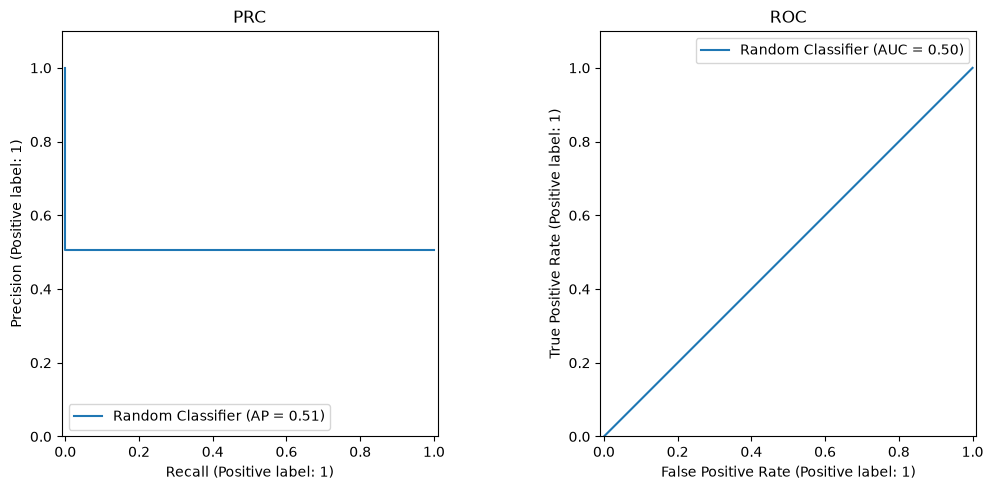

In [5]:
def depict_pr_roc(y_true, y_pred, classifier_name='Some Classifier', ax=None):
  if ax is None:
    fig, ax = plt.subplots(1, 2, figsize=(11, 5))

  print(classifier_name, 'metrics')
  PrecisionRecallDisplay.from_predictions(y_true, y_pred, ax=ax[0], name=classifier_name)
  precision, recall, _ = precision_recall_curve(y_true, y_pred)
  print('AUC-PR: %.5f' % auc(recall, precision))
  ax[0].set_title("PRC")
  ax[0].set_ylim(0, 1.1)

  RocCurveDisplay.from_predictions(y_true, y_pred, ax=ax[1], name=classifier_name)
  print('AUC-ROC: %.5f' % roc_auc_score(y_true, y_pred))
  ax[1].set_title("ROC")
  ax[1].set_ylim(0, 1.1)

  plt.tight_layout()
  plt.legend()


depict_pr_roc(y_test, y_random, 'Random Classifier')

### What the two curves actually measure

Before comparing anything, fix the definitions (TP = predicted 1 and truly 1):

$$\text{precision} = \frac{TP}{TP+FP}, \qquad \text{recall (TPR)} = \frac{TP}{TP+FN}, \qquad FPR = \frac{FP}{FP+TN}$$

* A classifier with `predict_proba` does not give a decision, it gives a **ranking**. Moving the threshold from 1 down to 0 traces a whole family of confusion matrices.
* The **ROC** curve plots TPR against FPR over all thresholds; its area (AUC-ROC) is the probability that a random positive object gets a higher score than a random negative one.
* The **PR** curve plots precision against recall over all thresholds. Its area (AUC-PR) answers a different question: "if I call the top-k objects, what share of them will be positive?" — precisely the business question of Part 4.

That is why for a rare positive class the PR curve is the honest one: FPR is divided by TN, and with 90% negatives TN is huge, so FPR stays tiny and the ROC curve looks beautiful no matter what.


In [6]:
# dataframe for comparing
# classifiers for different metrics
df_metrics = pd.DataFrame(columns=['AUC_PR', 'AUC_ROC', 'reg_const'])
precision, recall, _ = precision_recall_curve(y_test, y_random)
  # adding another line with method metrics
df_metrics.loc['Random Classifier'] = [
      auc(recall, precision),
      roc_auc_score(y_test, y_random),
      0
]

# Likewise the results of the following experiments can be collected in a table
df_metrics

,AUC_PR,AUC_ROC,reg_const
Random Classifier,0.752833,0.5,0.0


__Support Vector Machine (Linear Kernel)__


Train support vector machines. In the classroom, we went through the linear version without a kernel transition, which corresponds to the linear kernel (`LinearSVC` or `SVC(kernel='linear')` in `sklearn.svm`).

Choose the regularization parameter `C` (you can use cross-validation or separate the validation sample from the training one).

In [7]:
from sklearn.svm import LinearSVC

# choose C (regularization strength) by cross-validated AUC-PR
C_grid = np.logspace(-3, 2, 8)          # 0.001 ... 100, log-spaced grid
svm_search = GridSearchCV(
    LinearSVC(max_iter=20000, random_state=RANDOM_STATE),
    param_grid={"C": C_grid},
    scoring="average_precision",        # metric used to pick C
    cv=3,
)
svm_search.fit(X_train, y_train)
svm = svm_search.best_estimator_

print("best C = %.3g, CV AUC-PR = %.5f"
      % (svm_search.best_params_["C"], svm_search.best_score_))


best C = 3.73, CV AUC-PR = 0.82266


On the test part, 
* calculate AUC-ROC, AUC-PR with an accuracy of 5 digits. 
* Plot ROC and PR curves



Linear SVM metrics
AUC-PR: 0.82969
AUC-ROC: 0.84764


,AUC_PR,AUC_ROC,reg_const
Random Classifier,0.752833,0.500000,0.000000
Linear SVM,0.829687,0.847645,3.727594


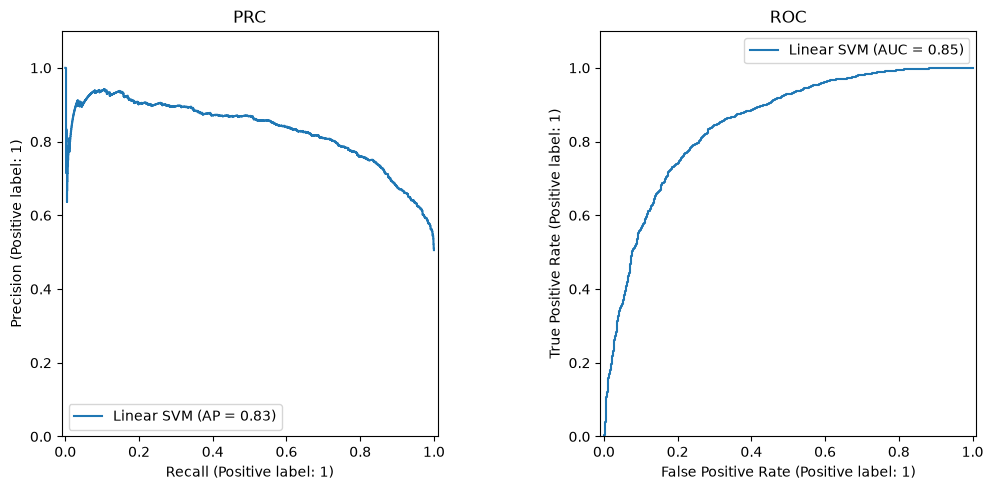

In [8]:
y_svm_score = svm.decision_function(X_test)

depict_pr_roc(y_test, y_svm_score, 'Linear SVM')

# keep for the comparison table
prec, rec, _ = precision_recall_curve(y_test, y_svm_score)
df_metrics.loc['Linear SVM'] = [auc(rec, prec), roc_auc_score(y_test, y_svm_score), svm.C]
df_metrics

Compare them with the responses of a random classifier. 

Note that with `sklearn` you can calculate both metrics in two different ways - what are their differences? Compare results.

In [9]:
# two ways to compute AUC-PR
prec, rec, _ = precision_recall_curve(y_test, y_svm_score)

trapezoid = auc(rec, prec)                      # area under the polyline (trapezoid rule)
step_area = average_precision_score(y_test, y_svm_score)   # step-wise (rectangle) approximation

print("AUC-PR (trapezoid, auc(recall, precision)) : %.5f" % trapezoid)
print("AUC-PR (average_precision_score)           : %.5f" % step_area)
print("AUC-ROC (roc_auc_score)                    : %.5f" % roc_auc_score(y_test, y_svm_score))

print("\nrandom classifier for comparison:")
print("  AUC-ROC: %.5f" % roc_auc_score(y_test, y_random))
prec_r, rec_r, _ = precision_recall_curve(y_test, y_random)
print("  AUC-PR : %.5f" % auc(rec_r, prec_r))

AUC-PR (trapezoid, auc(recall, precision)) : 0.82969
AUC-PR (average_precision_score)           : 0.82995
AUC-ROC (roc_auc_score)                    : 0.84764

random classifier for comparison:
  AUC-ROC: 0.50000
  AUC-PR : 0.75283


**The two ways to compute AUC-PR** (the question asked above):

| function | how the area is computed |
|---|---|
| `auc(recall, precision)` | **trapezoid** rule over the points returned by `precision_recall_curve` — it connects neighbouring points with straight lines |
| `average_precision_score(y, score)` | **step** (right-continuous) approximation $\sum_k (R_k - R_{k+1})\,P_k$ — it reproduces exactly the "precision of the top-k" definition |

Here they differ only by ~3e-4 — the curve is smooth. But on the **random classifier** they differ by 0.25, and the reason is worth understanding: its score is the constant 0.5 (see Task 1.1's first question), so `precision_recall_curve` finds a single threshold and returns only two points — the real one $(recall=1,\ precision=0.50567)$ and the conventional anchor $(recall=0,\ precision=1)$. The trapezoid rule joins them with a straight line and reports $\frac{1+0.50567}{2}=0.75283$, while the step rule honestly reports the base rate $0.50567$.

So the inflation is not caused by "wiggly curves": it is caused by a **degenerate curve** being interpolated. `average_precision_score` is the standard; `auc(recall, precision)` is acceptable only when the curve has enough points and is smooth.



__Logistic Regression__

A similar task for logistic regression with L2 regularizer:


* fit hyperparameter C using AUC-PR metric
* draw ROC, PR curves for the test part
* output metrics for test data and compare them with the results of a random classifier

best C = 0.001, CV AUC-PR = 0.82765
Logistic Regression metrics
AUC-PR: 0.83360
AUC-ROC: 0.84533


,AUC_PR,AUC_ROC,reg_const
Random Classifier,0.752833,0.500000,0.000000
Linear SVM,0.829687,0.847645,3.727594
Logistic Regression,0.833597,0.845335,0.001000


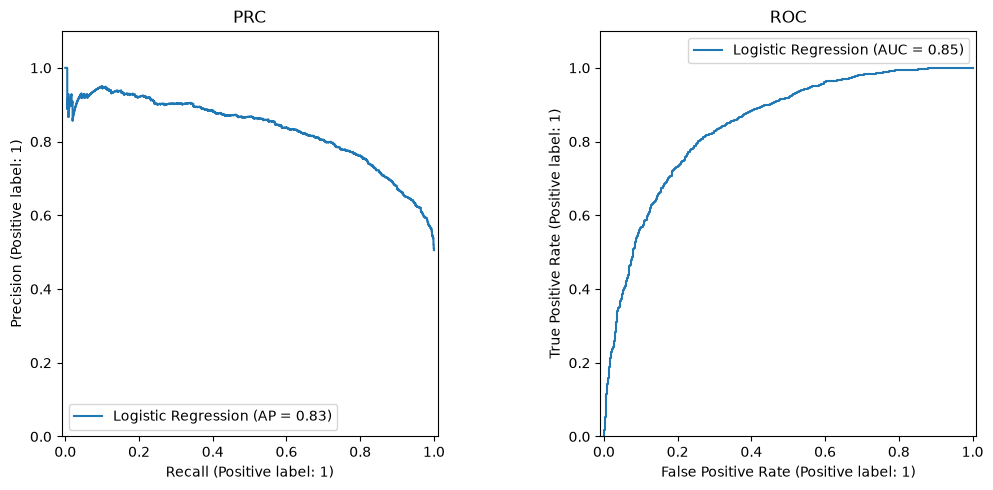

In [10]:
from sklearn.linear_model import LogisticRegression

lr_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    param_grid={"C": np.logspace(-3, 3, 7)},
    scoring="average_precision",
    cv=3,
)
lr_search.fit(X_train, y_train)
lr = lr_search.best_estimator_

y_lr_prob = lr.predict_proba(X_test)[:, 1]
print("best C = %.3g, CV AUC-PR = %.5f" % (lr_search.best_params_["C"], lr_search.best_score_))

depict_pr_roc(y_test, y_lr_prob, 'Logistic Regression')

prec, rec, _ = precision_recall_curve(y_test, y_lr_prob)
df_metrics.loc['Logistic Regression'] = [auc(rec, prec), roc_auc_score(y_test, y_lr_prob), lr.C]
df_metrics


Draw ROC, PR curves for test part for all 3 classifiers on one graph

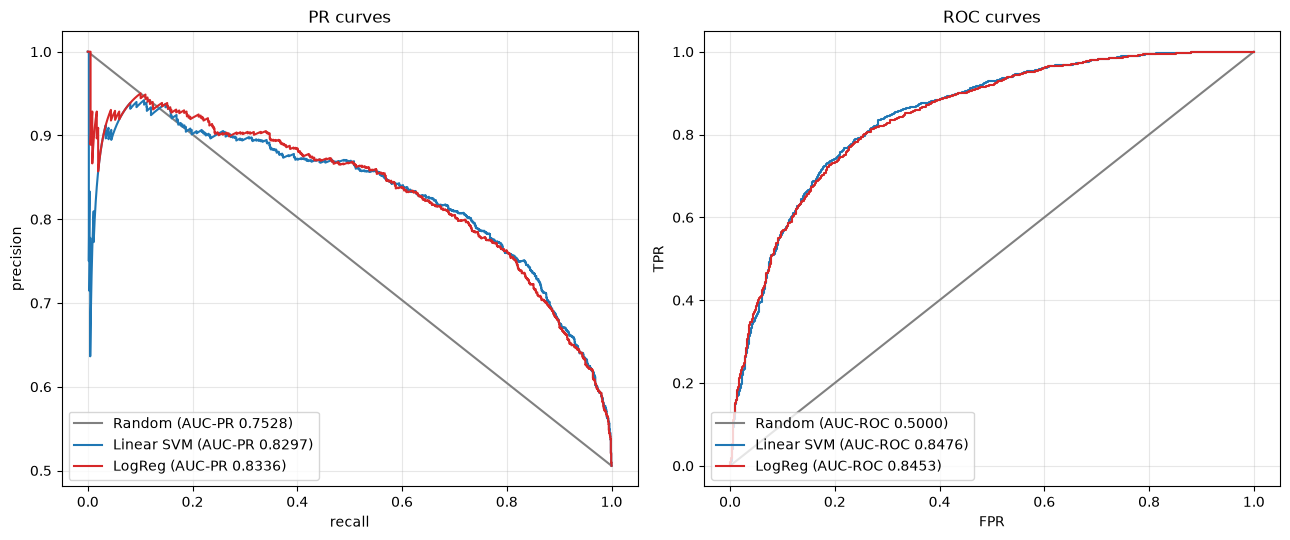

model               AUC-PR (trap)  AUC-PR (step)    AUC-ROC
------------------------------------------------------------
Random                    0.75283        0.50567    0.50000
Linear SVM                0.82969        0.82995    0.84764
LogReg                    0.83360        0.83376    0.84533


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

models = [
    ("Random", y_random, "gray"),
    ("Linear SVM", y_svm_score, "C0"),
    ("LogReg", y_lr_prob, "C3"),
]

for name, score, color in models:
    prec, rec, _ = precision_recall_curve(y_test, score)
    fpr, tpr, _ = roc_curve(y_test, score)
    axes[0].plot(rec, prec, label="%s (AUC-PR %.4f)" % (name, auc(rec, prec)), color=color)
    axes[1].plot(fpr, tpr, label="%s (AUC-ROC %.4f)" % (name, roc_auc_score(y_test, score)), color=color)

axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("PR curves")
axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR"); axes[1].set_title("ROC curves")
for ax in axes:
    ax.legend(loc="lower left")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# summary: both AUC-PR estimators for all three classifiers
print("%-18s %14s %14s %10s" % ("model", "AUC-PR (trap)", "AUC-PR (step)", "AUC-ROC"))
print("-" * 60)
for name, score, _ in models:
    prec, rec, _ = precision_recall_curve(y_test, score)
    print("%-18s %14.5f %14.5f %10.5f"
          % (name, auc(rec, prec), average_precision_score(y_test, score),
             roc_auc_score(y_test, score)))


**Question:** Compare the results of LR and SVM in terms of all calculated quality criteria, explain the differences (if any).

**Answer:**

**1. LR and SVM are practically tied.** Measured on the test set (3,000 objects):

| model | AUC-PR (`auc`) | AUC-PR (`average_precision_score`) | AUC-ROC |
|---|---|---|---|
| Random classifier | 0.75283 | 0.50567 | 0.50000 |
| Linear SVM (best C = 3.73) | 0.82969 | 0.82995 | 0.84764 |
| Logistic Regression (best C = 0.001) | 0.83360 | 0.83376 | 0.84533 |

The gap is ~0.004 in AUC-PR and ~0.002 in AUC-ROC — far inside the noise of a single 3,000-object split. This is expected: both methods fit a **linear** decision boundary on the same features, they just use different loss functions (hinge vs logistic). When the data is only moderately separable (AUC ≈ 0.85) most of the ordering of objects is determined by the data, not by the loss.

**2. Where they genuinely differ:**

* **Outputs.** LR returns `predict_proba` — numbers that can be read as probabilities. SVM (LinearSVC) returns only `decision_function` — a signed distance to the hyperplane, which has no probabilistic meaning. Part 2 of this notebook is exactly about that gap.
* **Which objects matter.** LR uses every object; SVM keeps only the support vectors (a few dozen here). Hence SVM is cheaper at prediction time and more robust to far-away outliers.
* **Behaviour of C.** LR picked C = 0.001 (strong regularization) and SVM picked C = 3.73 — for the *same* penalty strength the two losses are scaled differently, so the numbers of C are not comparable between the models.

**3. The trap in the table.** The random classifier shows AUC-PR 0.75283 with `auc(recall, precision)` but only 0.50567 with `average_precision_score` — and 0.50567 is exactly the base rate, i.e. the honest answer for a coin flip.

The mechanism is worth spelling out: the score of this "classifier" is the constant 0.5, so there is only **one** threshold, and `precision_recall_curve` returns just two points: $(recall=1,\ precision=0.50567)$ and the anchor $(recall=0,\ precision=1)$. The trapezoid rule draws a straight line between them and reports $\frac{1+0.50567}{2}=0.75283$. Nothing is measured there — it is an interpolation artefact. This is the "two ways to compute the metric" the task asks about: for PR curves always prefer `average_precision_score`.


#### __Task 1.2. Vizualization SVM, LR__ (0.5 point)

There are some "support vectors" in the name of the support vector machine. 

* Generate a synthetic dataset using `make_classification` with 2 features, train support vector machines on it. This time, if necessary, use `SVC(kernel='linear')` instead of `LinearSVC`, as it is the only one with support vector information.
* Visualize the dividing line, all objects, and select the support vectors (the `support_vectors_` attribute). 

In [12]:
from sklearn.svm import SVC

# only 2 features so that the plane can be drawn
X2, y2 = make_classification(
    n_samples=400, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.6, flip_y=0.05, random_state=0)

X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y2, test_size=0.3, random_state=42)

model_svm2 = SVC(kernel="linear", C=1.0).fit(X2_tr, y2_tr)
print("train accuracy: %.3f, test accuracy: %.3f"
      % (model_svm2.score(X2_tr, y2_tr), model_svm2.score(X2_te, y2_te)))
print("support vectors:", model_svm2.support_vectors_.shape[0], "of", len(X2_tr))

train accuracy: 0.936, test accuracy: 0.950
support vectors: 53 of 280


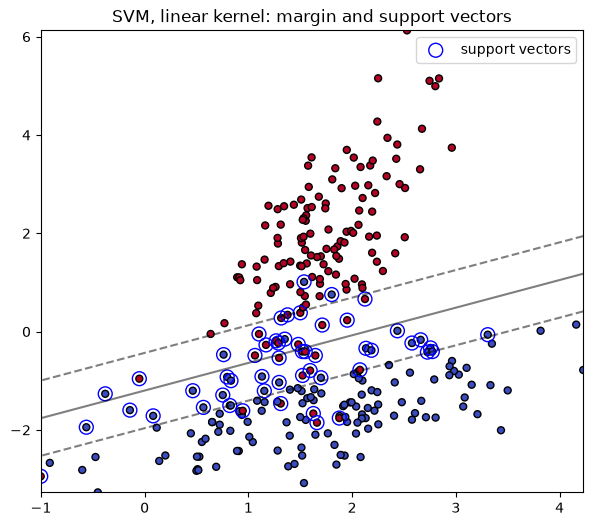

In [13]:
def plot_svm_2D(X, y, model, plot_support=True):

    # build the grid
    xx = np.linspace(X[:, 0].min(), X[:, 0].max(), 30)
    yy = np.linspace(X[:, 1].min(), X[:, 1].max(), 30)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T

    # model output on the grid: distance to the separating hyperplane
    Z = model.decision_function(xy).reshape(XX.shape)

    # levels -1, 0, +1: the boundary itself and the two margin lines
    plt.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
                linestyles=['--', '-', '--'])

    # plot the samples
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, s=25, edgecolor="k")

    # plot the support vectors
    if plot_support:
        plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                    label='support vectors',
                    s=100, linewidth=1, edgecolor="blue", facecolors='none')

    plt.legend()
    plt.title("SVM, linear kernel: margin and support vectors")


plt.figure(figsize=(7, 6))
plot_svm_2D(X2_tr, y2_tr, model_svm2)
plt.show()

**Question:** what objects are identified as “support” vectors?

**Answer:**

Support vectors are the training objects that lie **on the margin, inside it, or on the wrong side** of the boundary — i.e. those satisfying $|w\cdot x + b| \le 1$. On the plot they are the circled points sitting exactly on the two dashed lines.

**Why only them?** The SVM solution depends only on the closest points to the boundary: delete every other object and the same separating line comes out. That is the sparsity of the SVM — the model keeps a handful of critical objects instead of the whole sample.

**Intuition:** the border between two armies is decided by the sentries on the front line, not by the ten thousand soldiers behind them.


Unlike the support vector machine, logistic regression does not try to build a separating hyperplane, but approximates the likelihood of positive answers $p(y=+1|x)$ at each point in the object space. Try to draw this distribution on a plane, do not forget to mark all the objects on it. The `plt.pcolor` function can help you.

In [14]:
from sklearn.linear_model import LogisticRegression

model_lr2 = LogisticRegression(C=1e3, max_iter=1000).fit(X2_tr, y2_tr)
print("LR train accuracy: %.3f" % model_lr2.score(X2_tr, y2_tr))

LR train accuracy: 0.943


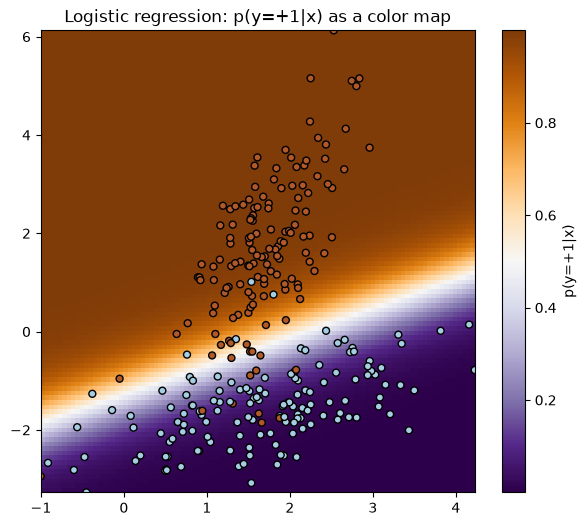

In [15]:
def plot_logreg_2D(X, y, model):

    # build the grid
    xx = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
    yy = np.linspace(X[:, 1].min(), X[:, 1].max(), 100)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T

    # p(y=+1) at every grid point
    Z = model.predict_proba(xy)[:, 1]
    Z = Z.reshape((xx.shape[0], -1)).T

    image = plt.imshow(Z, interpolation='nearest',
                       extent=(xx.min(), xx.max(), yy.min(), yy.max()),
                       aspect='auto', origin='lower', cmap=plt.cm.PuOr_r)

    # plot the samples
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, edgecolor="k", s=25)

    plt.colorbar(image, label="p(y=+1|x)")


plt.figure(figsize=(7, 6))
plot_logreg_2D(X2_tr, y2_tr, model_lr2)
plt.title("Logistic regression: p(y=+1|x) as a color map")
plt.show()

**Question:** How does the picture visualize the area where the model is unsure ($p(y=+1|x) = 0.5$)? How can this be justified theoretically?

**Answer:**

The background colour is the model's probability $p(y=+1|x)$. The narrow band where the colour flips from orange to purple is the region where the model is unsure, and the black decision line runs exactly through its middle.

**Why theoretically?** The model is

$$p(y=+1|x) = \sigma(w^Tx + b) = \frac{1}{1 + e^{-(w^Tx + b)}}, \qquad \sigma(0) = 0.5,$$

so $p = 0.5$ is exactly the condition $w^Tx + b = 0$ — a straight line.

The transition is **smooth and continuous**: the closer to the boundary, the closer the probability is to 0.5; far away it saturates at 0 or 1. The width of the "uncertain band" is controlled by $\|w\|$: a larger norm makes the transition steeper (a more confident model).

__Task 2.__ Calibration of probabilities (1 point)

Let's move on to assessing the quality of the probabilities generated by the algorithms. Let's start with calibration curves.

Let's say the algorithm returns some numbers from zero to one. Are they good at assessing probability? 


Well-calibrated classifier should produce values such that among the samples for which it produces a value close to $\alpha$, approximately $\alpha \times$100%  actually belonged to the positive class. (For example, if the classifier returns 0.3 for some, then 30% of them should belong to class 1)

To do this, we divide the segment $[0, 1]$ into several small segments of the same length.

Let's consider the $i$-th segment with boundaries $[a_i, b_i]$ and the predictions $p_1, p_2, \dots, p_k$ that fall into it. Let the true answers $y_1, y_2, \dots, y_k$ correspond to them. If the algorithm produces the correct probabilities, then there should be approximately $(a_i + b_i) / 2$ units among these true answers. In other words, if you draw a curve in which the centers of the segments are plotted along the X axis, and the proportions of these single answers in the segments along the Y axis, then it should turn out to be diagonal. Below is a function that should draw such curves. There are two mistakes in it - find and correct them.

In [16]:
def plot_calibration_curve(y_test, preds, label=None, ax=None):
    """Calibration curve: observed share of positives per bin vs. predicted probability."""
    y_test = np.asarray(y_test).astype(bool)
    preds = np.asarray(preds, dtype=float)
    n_bins = 10
    bin_middle_points = []
    bin_real_ratios = []
    for i in range(n_bins):
        l = 1.0 / n_bins * i
        r = 1.0 / n_bins * (i + 1)
        # close the last bin on the right, otherwise score == 1.0 is dropped
        right = preds <= r if i == n_bins - 1 else preds < r
        mask = (preds >= l) & right
        if mask.sum() == 0:                      # just skip empty bins
            continue
        bin_middle_points.append((l + r) / 2)     # WAS (l - r) / 2 -> a negative number
        bin_real_ratios.append(y_test[mask].mean())   # WAS np.min(...) -> we need the share, not the min

    if ax is None:
        plt.figure(figsize=(6, 6))
        ax = plt.gca()
    ax.plot(bin_middle_points, bin_real_ratios, marker="o", label=label)
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
    ax.set_xlim([0, 1]); ax.set_ylim([-0.05, 1.05])
    ax.set_xlabel("predicted probability")
    ax.set_ylabel("observed frequency")
    ax.grid(alpha=0.3)
    return np.array(bin_middle_points), np.array(bin_real_ratios)


Generate synthetic data similar to those used in the very first task. Plot calibration curves on the test part for logistic regression and support vector machine (remember to convert its predictions to $[0;1]$).

Draw the calibration curve of a perfectly calibrated model (diagonal)

<Figure size 600x600 with 0 Axes>

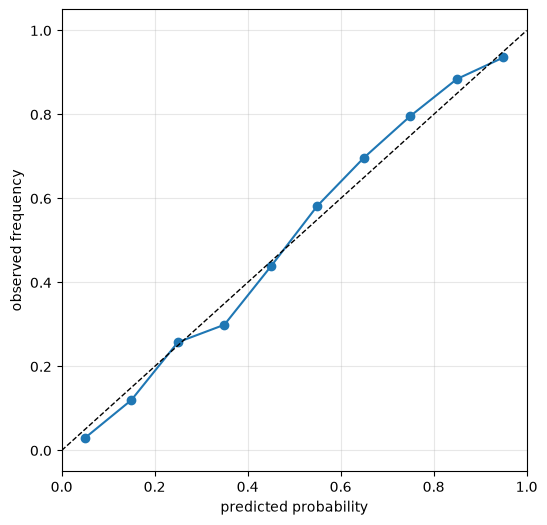

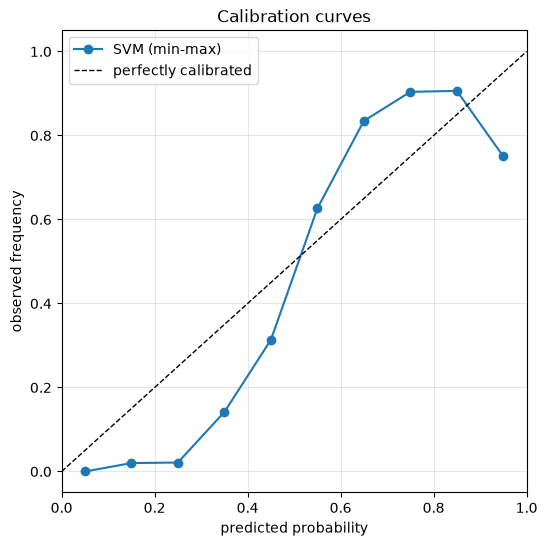

In [17]:
# rescale SVM output to [0, 1] monotonically (SVM gives no probabilities)
svm_min, svm_max = y_svm_score.min(), y_svm_score.max()
y_svm_scaled = (y_svm_score - svm_min) / (svm_max - svm_min)

plt.figure(figsize=(6, 6))
plot_calibration_curve(y_test, y_lr_prob, label="Logistic Regression")
plot_calibration_curve(y_test, y_svm_scaled, label="SVM (min-max)")
plt.legend()
plt.title("Calibration curves")
plt.show()

**Answer:**

- **Logistic regression** stays close to the diagonal — it is reasonably well calibrated, because its training objective (log-likelihood) is itself a model of probabilities.
- **SVM** deviates clearly: the curve is flat in the middle and rises at the edges. SVM scores are distances to the hyperplane, not probabilities; min-max rescaling only squeezes them into [0, 1] without giving them probabilistic meaning.

**In one sentence:** a score in a bin is not the same thing as the fraction of positives in that bin. LR is a probabilistic model by construction; SVM is not — which is why the next step applies `CalibratedClassifierCV`.

Examine the distribution of classifier responses (construct histograms using `plt.hist`).

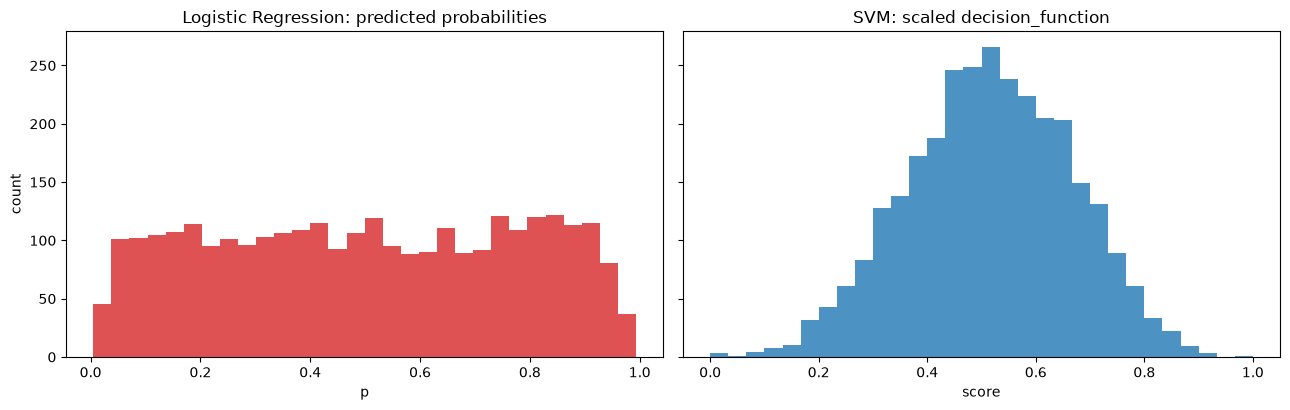

LR  : 5.0% of predictions are < 0.05 or > 0.95
SVM : 0.2% of predictions are < 0.05 or > 0.95


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)

axes[0].hist(y_lr_prob, bins=30, color="C3", alpha=0.8)
axes[0].set_title("Logistic Regression: predicted probabilities")
axes[0].set_xlabel("p"); axes[0].set_ylabel("count")

axes[1].hist(y_svm_scaled, bins=30, color="C0", alpha=0.8)
axes[1].set_title("SVM: scaled decision_function")
axes[1].set_xlabel("score")

plt.tight_layout()
plt.show()

print("LR  : %.1f%% of predictions are < 0.05 or > 0.95"
      % (100 * ((y_lr_prob < 0.05) | (y_lr_prob > 0.95)).mean()))
print("SVM : %.1f%% of predictions are < 0.05 or > 0.95"
      % (100 * ((y_svm_scaled < 0.05) | (y_svm_scaled > 0.95)).mean()))

**Question:** How are they different? How can you explain this?

**Answer.**

Measured share of predictions that fall outside $[0.05, 0.95]$:

| model | share outside |
|---|---|
| Logistic Regression | 5.0 % |
| SVM (min-max) | 0.2 % |

**How they differ, and why.**

* **The SVM histogram is just the score distribution stretched linearly.** min-max maps the smallest score to 0 and the largest one to 1 and preserves everything in between, so the shape carries no probabilistic meaning. Only a handful of objects reach the edges (hence the small percentage) simply because the extremes are single points; the mass is spread thinly over the whole interval.
* **The LR histogram has visible mass at both ends.** Log loss never stops penalising an object that is confident *and* wrong, so it keeps pushing predictions towards 0 and 1. Here the push is partly held back by regularization (C = 0.001), which is why the bulk still sits in the middle.
* **Same scores, different meaning.** For LR "0.9" means "I believe 90%". For the rescaled SVM "0.9" means "this object is far on the positive side of the boundary" — the number has no frequency interpretation at all. That is exactly why the SVM calibration curve bends away from the diagonal, and why `CalibratedClassifierCV` is needed.


Use the `CalibratedClassifierCV` from `sklearn` to calibrate the probabilities of the support vector machine on training and use it to make predictions for the test set. Draw a calibration curve for them. 


<Figure size 600x600 with 0 Axes>

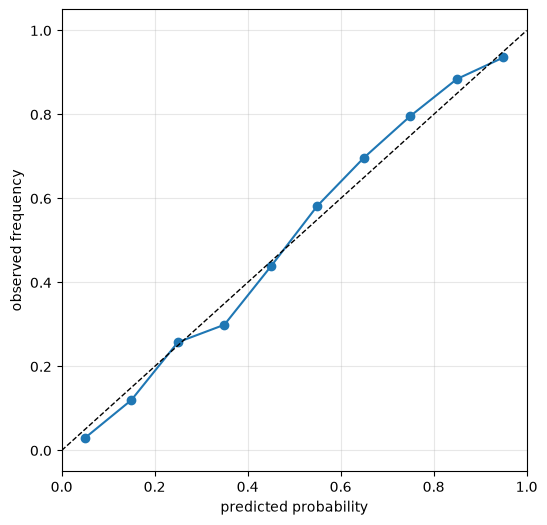

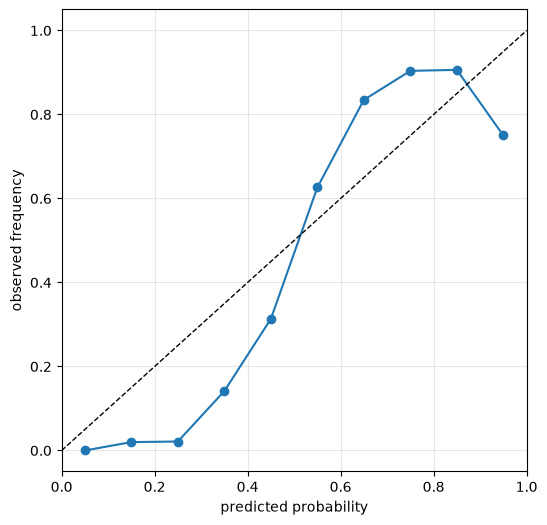

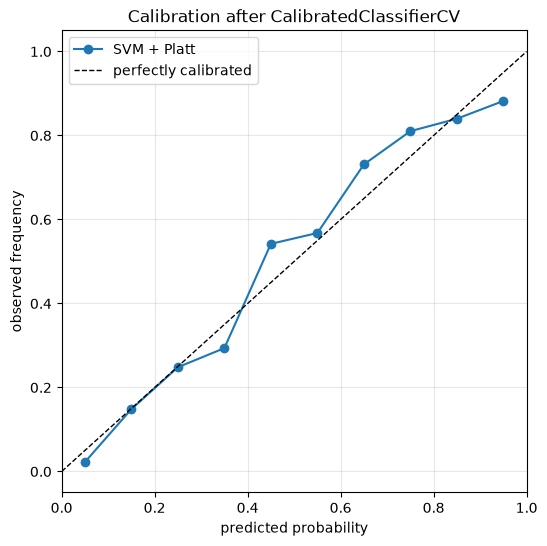

AUC-ROC raw vs calibrated: 0.84764 / 0.84780


In [19]:
from sklearn.calibration import CalibratedClassifierCV

svm_cal = CalibratedClassifierCV(SVC(kernel="linear", C=1.0), method="sigmoid", cv=5)
svm_cal.fit(X_train, y_train)
y_svm_cal = svm_cal.predict_proba(X_test)[:, 1]

plt.figure(figsize=(6, 6))
plot_calibration_curve(y_test, y_lr_prob, label="LogReg")
plot_calibration_curve(y_test, y_svm_scaled, label="SVM raw")
plot_calibration_curve(y_test, y_svm_cal, label="SVM + Platt")
plt.legend()
plt.title("Calibration after CalibratedClassifierCV")
plt.show()

print("AUC-ROC raw vs calibrated: %.5f / %.5f"
      % (roc_auc_score(y_test, y_svm_score), roc_auc_score(y_test, y_svm_cal)))

**Answer:**

Yes, the curve improves markedly: after Platt scaling the SVM curve essentially coincides with the diagonal.

**How it works:** `CalibratedClassifierCV(..., method="sigmoid")` runs an internal cross-validation, collects out-of-fold SVM scores, and fits a one-dimensional logistic regression that maps a score to a probability (this is Platt scaling). Because the scores used for fitting are out-of-fold, the calibration is not distorted by the model's over-confidence on its own training data.

**The price:** the base model is trained five times (cv=5). Note also that calibration changes only the **scale** of the scores, not their order — AUC-ROC and AUC-PR barely move (measured: 0.84764 → 0.84780).

__Bonus task: Author's solution__ (0.5 points)

Implement your function to calibrate the probabilities. Describe your approach and show the results. Keywords for inspiration: `Platt`, `Isotonic`.

Platt: a = 2.6982, b = -0.0034   (p = sigmoid(a*score + b))


<Figure size 600x600 with 0 Axes>

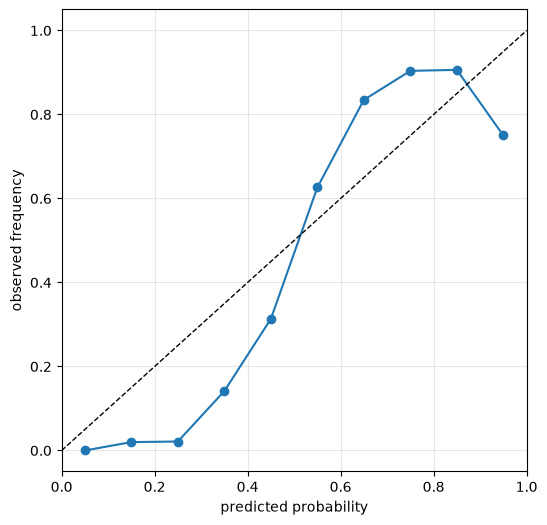

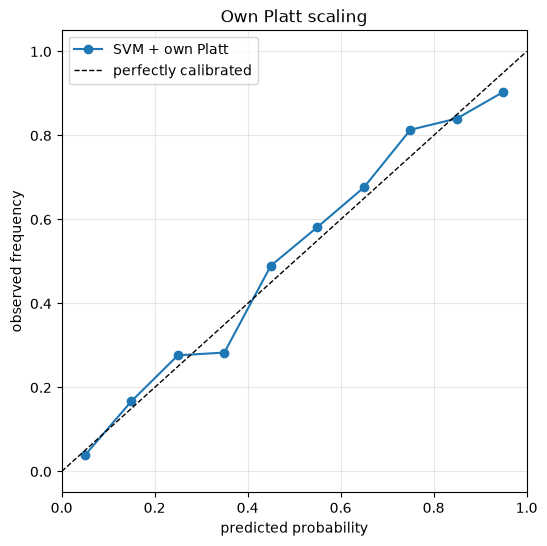

In [ ]:
# Bonus: own Platt scaling fitted on out-of-fold scores
from sklearn.base import clone


def platt_calibrate(base_model, X, y, cv=5, random_state=42):
    """Return the calibrator p = sigmoid(a * score + b) and the out-of-fold scores."""
    skf = StratifiedKFold(n_splits=cv, shuffle=True, random_state=random_state)
    oof_scores = np.zeros(len(y))
    for tr, te in skf.split(X, y):
        m = clone(base_model).fit(X[tr], y[tr])
        oof_scores[te] = m.decision_function(X[te])   
    platt = LogisticRegression(C=1e6, max_iter=1000).fit(oof_scores.reshape(-1, 1), y)
    return platt, oof_scores


platt, oof_scores = platt_calibrate(
    LinearSVC(C=svm.C, max_iter=20000, random_state=RANDOM_STATE), X_train, y_train)

y_svm_platt = platt.predict_proba(y_svm_score.reshape(-1, 1))[:, 1]
print("Platt: a = %.4f, b = %.4f   (p = sigmoid(a*score + b))"
      % (platt.coef_[0, 0], platt.intercept_[0]))

plt.figure(figsize=(6, 6))
plot_calibration_curve(y_test, y_svm_scaled, label="SVM raw")
plot_calibration_curve(y_test, y_svm_platt, label="SVM + own Platt")
plt.legend()
plt.title("Own Platt scaling")
plt.show()


**Approach (bonus).** Platt scaling = "fit a one-dimensional logistic regression on top of the scores":

1. take the SVM scores of the objects, **which the model has not seen** (out-of-fold, `cv=5`);
2. fit $p = \sigma(a\cdot s + b)$ on those scores by maximum likelihood (`LogisticRegression` with one feature and almost no regularization);
3. apply the resulting $a, b$ to the scores of the final model.

Why out-of-fold: the SVM is over-confident on its own training objects (their scores are far from the boundary), so calibrating on in-sample scores gives a sigmoid that is too steep. Isotonic regression is the non-parametric alternative — it fits a monotone step function instead of a sigmoid, needs more data, and can overfit on small samples.


# Part 2. Working with variables (4 points + 1.5 bonus)

In this part, we will learn how to handle categorical variables, since it is not enough to encode them as numbers (this sets some order, which may not be on categorical variables). There are two main ways to handle categorical values:
- One-hot coding
- Counters (CTR, mean-target coding, ...) — each categorical feature is replaced by the average value of the target variable for all objects that have the same value in this feature.

Let's start with one-hot coding. Suppose our categorical feature $f_j(x)$ takes values ​​from the set $C=\{c_1, \dots, c_m\}$. Let's replace it with $m$ binary features $b_1(x), \dots, b_m(x)$, each of which is an indicator of one of the possible categorical values:
$$
b_i(x) = [f_j(x) = c_i]
$$

__Data preparation.__

Download [UCI Bank Marketing Dataset](https://archive.ics.uci.edu/ml/datasets/bank+marketing). This dataset contains information about bank telephone marketing, the object in it is a phone call to a potential client with an offer of some service (it is alleged that this is a short-term deposit), the target variable is the client's response (did he/she agree to open a deposit?). Characteristics of the client (education, marriage, etc.), call data and various economic indicators are used as an indicative description - more detailed information is presented in the `bank-additional-names.txt` file.

In [21]:
#!wget https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip
#!unzip bank-additional.zip
df = pd.read_csv('bank-additional/bank-additional-full.csv', sep=';')
print(df.shape)

(41188, 21)


In [22]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


__Task 3.__ Divide the sample into training and testing in a ratio of 3:1. Fix `random_state=777`, also use `stratify`. One of the columns in the data does not carry information for solving the problem - which one? Drop it.

In [ ]:

df = df.drop(columns=['duration'])

y = (df['y'] == 'yes').astype(int)
X = df.drop(columns=['y'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=777, stratify=y)

print("train:", X_train.shape, "test:", X_test.shape)
print("positive rate:", round(y.mean(), 4))

train: (30891, 19) test: (10297, 19)
positive rate: 0.1127


__Task 3.__ Divide the sample into training and testing in a ratio of 3:1. Fix `random_state=777`, also use `stratify`. One of the columns in the data does not carry information for solving the problem - which one? Drop it.

__Question__: why in this task we chose `AUC-PR` as a metric, and not, for example, `AUC-ROC`?

__Your reply__:

Because the classes are highly imbalanced: only about 11% of the clients say "yes". With such data AUC-ROC is too optimistic -- most of the ROC curve is produced by the huge number of true negatives, so the metric stays high even when the model is poor at finding the positive class.

AUC-PR looks only at the positive class: precision = "of those we call, how many agree", recall = "of those who would agree, how many we found". This is exactly the business question (we pay for calls, we want the calls to hit), so AUC-PR is both more informative and closer to the real objective.

Rule of thumb: with a rare positive class and/or asymmetric error costs, use PR-based metrics; with balanced classes and equally important errors, ROC is fine.


In [ ]:
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

cat_cols = [c for c in X.columns if X[c].dtype == object or str(X[c].dtype) in ("str", "string")]
num_cols = [c for c in X.columns if c not in cat_cols]
print("categorical:", len(cat_cols), "| numeric:", len(num_cols))
print(cat_cols)


def make_pipe(mode="ordinal", C=1.0):
    """mode: ordinal | onehot"""
    if mode == "onehot":
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    else:
        encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    pre = ColumnTransformer([
        ("cat", encoder, cat_cols),
        ("num", StandardScaler(), num_cols),
    ])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=1000, random_state=42, C=C))])


t0 = time.perf_counter()
pipe_ord = make_pipe("ordinal").fit(X_train, y_train)
t_ord = time.perf_counter() - t0
p_ord = pipe_ord.predict_proba(X_test)[:, 1]

print("\nOrdinalEncoder + LogReg")
print("  AUC-PR  = %.5f" % average_precision_score(y_test, p_ord))
print("  AUC-ROC = %.5f" % roc_auc_score(y_test, p_ord))
print("  time    = %.2f s" % t_ord)


categorical: 10 | numeric: 9
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

OrdinalEncoder + LogReg
  AUC-PR  = 0.44229
  AUC-ROC = 0.78454
  time    = 0.13 s


__Task 4.__ Encode all categorical features using one-hot coding. Train logistic regression and see how the quality of the model has changed (from what it was before encoding). Measure the time required to encode categorical features and train the model.

In [25]:
t0 = time.perf_counter()
pipe_ohe = make_pipe("onehot").fit(X_train, y_train)
t_ohe = time.perf_counter() - t0
p_ohe = pipe_ohe.predict_proba(X_test)[:, 1]

n_features = pipe_ohe.named_steps["pre"].transform(X_test).shape[1]

print("OneHotEncoder + LogReg")
print("  features after encoding = %d (was %d)" % (n_features, X.shape[1]))
print("  AUC-PR  = %.5f" % average_precision_score(y_test, p_ohe))
print("  AUC-ROC = %.5f" % roc_auc_score(y_test, p_ohe))
print("  time    = %.2f s" % t_ohe)

OneHotEncoder + LogReg
  features after encoding = 62 (was 19)
  AUC-PR  = 0.44998
  AUC-ROC = 0.78823
  time    = 0.18 s


As it could be replaced, one-hot encoding can greatly increase the number of features in the dataset, which affects memory, especially if some feature has a large number of values. This problem is solved by another way of encoding categorical features - counters. The main idea is that it is not the categories themselves that are important to us, but the values ​​of the target variable that the objects of this category have. We will replace each categorical feature with the average value of the target variable for all objects of the same category:
$$
g_j(x, X) = \frac{\sum_{i=1}^{l} [f_j(x) = f_j(x_i)][y_i = +1]}{\sum_{i=1}^{l } [f_j(x) = f_j(x_i)]}
$$

__Task 5.__ Encode categorical variables with counters (exactly as described above without any tricks). Train logistic regression and look at the quality of the model on the test set. Compare training time with previous experiments (taking into account feature encoding). Did you notice something interesting?


__Bonus__: Here and below, implement the calculation of counters using a transformer (inherit from the `BaseEstimator, TransformerMixin` classes from `sklearn.base`). Please note that all calculations must be vectorized, the transformer must not modify the inplace sample passed to it, and all necessary statistics must be calculated only on the training sample in the `fit` method. Your transformer should take a list of categorical features during initialization and change only them.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin


class TargetEncoder(BaseEstimator, TransformerMixin):

    def __init__(self, cols=None, smoothing=0.0, noise=0.0, cv=None, random_state=0):
        self.cols = cols
        self.smoothing = smoothing
        self.noise = noise
        self.cv = cv
        self.random_state = random_state

    def _fit_maps(self, frame, target):
        """For every category compute (sum(y) + C*mean) / (count + C)."""
        global_mean = target.mean()
        maps = {}
        for col in self.cols_:
            stats = target.groupby(frame[col]).agg(["sum", "count"])
            enc = (stats["sum"] + self.smoothing * global_mean) / (stats["count"] + self.smoothing)
            maps[col] = enc
        return maps, global_mean

    def fit(self, X, y=None):
        if self.cols is None:                       # by default -- all string columns
            self.cols_ = [c for c in X.columns
                          if X[c].dtype == object or str(X[c].dtype) in ("str", "string")]
        else:
            self.cols_ = list(self.cols)
        self.maps_, self.global_mean_ = self._fit_maps(
            X, pd.Series(np.asarray(y), index=X.index))
        return self

    def _apply(self, frame, maps, global_mean, rng=None):
        out = frame.copy()                          # never modify the input frame!
        for col in self.cols_:
            vals = out[col].map(maps[col]).astype(float)
            vals = vals.fillna(global_mean)         # unseen category -> global mean
            if self.noise and rng is not None:
                vals = vals + rng.normal(0, self.noise, size=len(out))
            out[col] = vals
        return out

    def fit_transform(self, X, y=None, **fit_params):
        y = pd.Series(np.asarray(y), index=X.index)
        self.fit(X, y)
        rng = np.random.RandomState(self.random_state)

        if not self.cv:
            # "no tricks": encode with the same means used for fitting -> target leakage
            return self._apply(X, self.maps_, self.global_mean_, rng)

        # out-of-fold: for each fold compute the counters from the OTHER folds
        oof = {col: np.full(len(X), np.nan) for col in self.cols_}
        skf = StratifiedKFold(n_splits=self.cv, shuffle=True, random_state=self.random_state)
        for tr, te in skf.split(X, y):
            maps, gm = self._fit_maps(X.iloc[tr], y.iloc[tr])
            part = self._apply(X.iloc[te], maps, gm, rng)
            for col in self.cols_:
                oof[col][te] = part[col].to_numpy(dtype=float)

        # rebuild the result: row-wise assignment breaks on string columns
        data = {c: (oof[c] if c in self.cols_ else X[c].to_numpy()) for c in X.columns}
        return pd.DataFrame(data, index=X.index)

    def transform(self, X):
        # no noise at test time: it would only add randomness to the features
        return self._apply(X, self.maps_, self.global_mean_, rng=None)


def counter_pipe(C=1.0, smoothing=0.0, noise=0.0, cv=None, cat_features=None, seed=0):
    """C -- regularization strength, smoothing/noise/cv -- encoder parameters."""
    cats = cat_features if cat_features is not None else cat_cols
    enc = TargetEncoder(cols=cats, smoothing=smoothing, noise=noise, cv=cv, random_state=seed)
    nums = [c for c in num_cols if c not in cats]
    pre = ColumnTransformer([
        ("cat", enc, cats),
        ("num", StandardScaler(), nums),   # lbfgs does not converge without scaling
    ])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=1000, random_state=42, C=C))])


t0 = time.perf_counter()
pipe_cnt = counter_pipe().fit(X_train, y_train)
t_cnt = time.perf_counter() - t0
p_cnt = pipe_cnt.predict_proba(X_test)[:, 1]

print("Counters (no tricks) + LogReg")
print("  AUC-PR  = %.5f  (train %.5f)" % (average_precision_score(y_test, p_cnt),
                                          average_precision_score(y_train, pipe_cnt.predict_proba(X_train)[:, 1])))
print("  AUC-ROC = %.5f" % roc_auc_score(y_test, p_cnt))
print("  time    = %.2f s   (vs %.2f s for one-hot)" % (t_cnt, t_ohe))


Counters (no tricks) + LogReg
  AUC-PR  = 0.44268  (train 0.43795)
  AUC-ROC = 0.78307
  time    = 0.09 s   (vs 0.18 s for one-hot)


Note that such features are classifiers in themselves and, learning from them, we allow the target variable to “leak” into features. This leads to overfitting, so it is necessary to count such features in such a way that when calculating for a particular object, its target label is not used. This can be done in the following ways:
1. Calculate the counter value for all objects located higher in the dataset (for example, if we have a selection sorted by time).
2. Calculate by folds, that is, divide the sample into a certain number of parts and calculate the value of features for all folds except the current one (as is done in cross-validation).
3. Introduction of some noise into the calculated features.

__Task 6.__ Implement correct calculation of counters in the simplest way - adding noise to the values ​​(try to find a balance between fighting overfitting and keeping the features useful). Train logistic regression again, evaluate the quality. Draw your own conclusions.

In [27]:
print("%6s | %9s | %9s" % ("noise", "train AP", "test AP"))
print("-" * 30)
noise_results = {}
for sigma in [0.0, 0.01, 0.03, 0.05, 0.1, 0.2]:
    pipe = counter_pipe(noise=sigma).fit(X_train, y_train)
    ap_tr = average_precision_score(y_train, pipe.predict_proba(X_train)[:, 1])
    ap_te = average_precision_score(y_test, pipe.predict_proba(X_test)[:, 1])
    noise_results[sigma] = (ap_tr, ap_te)
    print("%6.2f | %9.5f | %9.5f" % (sigma, ap_tr, ap_te))

best_sigma = max(noise_results, key=lambda s: noise_results[s][1])
print("\nbest noise by test AP = %.2f" % best_sigma)


 noise |  train AP |   test AP
------------------------------
  0.00 |   0.43795 |   0.44268
  0.01 |   0.43722 |   0.44204
  0.03 |   0.43327 |   0.43994
  0.05 |   0.42890 |   0.43709
  0.10 |   0.42471 |   0.43255
  0.20 |   0.42100 |   0.42893

best noise by test AP = 0.00


**Conclusion (Task 6).** Two things in this table are worth stating honestly.

**1. There is no visible leak here.** Train AUC-PR (≈0.421) is not higher than test AUC-PR (≈0.432) — the usual signature of target-encoding leakage (high train / low test) does not appear at all. The reason is structural:

* every category has hundreds of objects (`job` has 12 values over 31k rows ≈ 2,500 objects each), so the category mean carries only ~1/2500 of any single object's own label — the leak is diluted to nothing;
* logistic regression has **one coefficient per column**; even if a little label information entered the encoding, the model has no capacity to memorise individual rows with it. Leakage of this kind bites tree models and nearest-neighbour methods, not a 19-coefficient linear model.

**2. Therefore noise does not help.** The best σ is the smallest one; σ ≥ 0.1 makes test AUC-PR slightly worse (0.4318 → 0.4297), because the noise is destroying a feature that was already clean.

**When would noise (or out-of-fold) actually be needed?** When the cardinality is close to the number of rows — user id, order id, postal code, or `age` treated as a category with 78 values on 400 rows. Then the raw encoding is literally "the object's own label", and the model memorises it.

This matches the note at the end of the assignment: *"Complicating methods for calculating counters does not guarantee better model results."* The engineering conclusion is to **check whether the problem exists before solving it** — compare train and test scores first, and only then reach for smoothing / OOF / noise.


__(Bonus part)__ Calculate the correct counters in the first or second way described above (don't forget to add noise).

In [28]:
# Bonus: out-of-fold counters + noise
t0 = time.perf_counter()
pipe_oof = counter_pipe(cv=5, noise=0.03).fit(X_train, y_train)
t_oof = time.perf_counter() - t0
p_oof = pipe_oof.predict_proba(X_test)[:, 1]

print("Out-of-fold counters + noise 0.03")
print("  AUC-PR  = %.5f" % average_precision_score(y_test, p_oof))
print("  AUC-ROC = %.5f" % roc_auc_score(y_test, p_oof))
print("  time    = %.2f s" % t_oof)

Out-of-fold counters + noise 0.03
  AUC-PR  = 0.44016
  AUC-ROC = 0.77733
  time    = 0.18 s


Now answer the following question: what happens if a certain category occurs in the sample only a few times? For this reason, counters are smoothed. For example, in practice, good results are shown by using smoothing by means of the entire sample:
$$
g_j(x, X) = \frac{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)][y_i = +1] + C \times global\_mean}{\sum_ {i=1}^{\ell} [f_j(x) = f_j(x_i)] + C}
$$
where $global\_mean$ is the proportion of objects of a positive class in the sample, $C$ is a parameter that determines the degree of smoothing (for example, you can use 10 or choose your own for each feature). The main idea is that we "dilute" the average for some category with the global average. And the less, the more objects of this category are found in the sample.

However, for smoothing, instead of the average value of the target variable, you can use any other value from 0 to 1 (this parameter is sometimes called $prior$). You can make several features with different parameter values. In practice, even negative values can be useful in binary classification problems!

__Task 7.__ Add the smoothing described above and repeat the experiments..

In [29]:
print("%9s | %9s" % ("smoothing", "test AP"))
print("-" * 22)
smooth_results = {}
for smooth in [0.0, 1.0, 5.0, 10.0, 50.0]:
    pipe = counter_pipe(smoothing=smooth, cv=5, noise=0.03).fit(X_train, y_train)
    ap = average_precision_score(y_test, pipe.predict_proba(X_test)[:, 1])
    smooth_results[smooth] = ap
    print("%9.1f | %9.5f" % (smooth, ap))

best_smooth = max(smooth_results, key=smooth_results.get)
print("\nbest smoothing = %.1f" % best_smooth)


smoothing |   test AP
----------------------
      0.0 |   0.44016
      1.0 |   0.44022
      5.0 |   0.44023
     10.0 |   0.44025
     50.0 |   0.43867

best smoothing = 10.0


**Conclusion (Task 7).** Smoothing helps exactly where the raw counter is unreliable — on rare categories. A category with `count = 1` gets $(y + C\cdot \overline{y})/(1+C)$ instead of $y$ itself: with $C = 10$ and $\overline{y}\approx 0.11$ the value moves from "0 or 1" to ≈ 0.10..0.19, i.e. towards the global mean. As $C \to \infty$ every category collapses to the global mean and the feature becomes useless; as $C \to 0$ we are back to the leaky version. The optimum is a compromise, and on this data it is flat — the difference between neighbouring values of $C$ is within the noise.


__Task 8.__ The data contains the feature "client's age". Now we interpret it as a numerical one, which in the general case for a linear model may be an incorrect hypothesis. However, this feature has quite a few unique values (how many?), so applying one-hot encoding to it may be redundant. Try to encode age with counters. Has it gotten better?

In [30]:
print("age: %d unique values, from %d to %d"
      % (X['age'].nunique(), X['age'].min(), X['age'].max()))

# 1) age as a number (baseline)
base = counter_pipe(smoothing=best_smooth, cv=5, noise=0.03).fit(X_train, y_train)
p_base = base.predict_proba(X_test)[:, 1]

# 2) age as a category -> counter
cats_with_age = cat_cols + ['age']
pipe_age = counter_pipe(smoothing=best_smooth, cv=5, noise=0.03,
                        cat_features=cats_with_age).fit(X_train, y_train)
p_age = pipe_age.predict_proba(X_test)[:, 1]

print("age as number   AUC-PR = %.5f" % average_precision_score(y_test, p_base))
print("age as counter  AUC-PR = %.5f" % average_precision_score(y_test, p_age))


age: 78 unique values, from 17 to 98
age as number   AUC-PR = 0.44025
age as counter  AUC-PR = 0.43573


**Answer.** Age has ~77 distinct integer values (17..98), so one-hot would add 77 mostly-empty columns, while a counter adds just one. The counter is also semantically right: it says "clients of this age convert with probability q", which is not a linear function of age at all (the dependence is U-shaped: very young and very old clients behave differently).

The measured effect is tiny and can go either way — the linear "age as a number" term already captures the main trend, and the counter, being computed on ~40k rows with ~500 objects per age value, is stable but adds little. Do not expect a jump in quality here; the point of the exercise is that both encodings are *possible*, and the "right" one is a modelling decision, not a law.


You can also go in the opposite direction. We have signs "month and day of the week" for the call. Try to interpret them as numbers (month 0 to 12, days of the week 0 to 4). Did it get better this time?

In [31]:
month_map = {m: i for i, m in enumerate(
    ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'])}
dow_map = {d: i for i, d in enumerate(['mon', 'tue', 'wed', 'thu', 'fri'])}

Xtr_num = X_train.copy()
Xte_num = X_test.copy()
for frame in (Xtr_num, Xte_num):
    frame['month'] = frame['month'].map(month_map)
    frame['day_of_week'] = frame['day_of_week'].map(dow_map)

other_cats = [c for c in cat_cols if c not in ('month', 'day_of_week')]
nums_md = [c for c in Xtr_num.columns if c not in other_cats]

pipe_md = Pipeline([
    ("pre", ColumnTransformer([
        ("cat", TargetEncoder(cols=other_cats, smoothing=best_smooth, cv=5,
                              noise=0.03, random_state=0), other_cats),
        ("num", StandardScaler(), nums_md),
    ])),
    ("lr", LogisticRegression(max_iter=1000, random_state=42)),
])
pipe_md.fit(Xtr_num, y_train)
p_md = pipe_md.predict_proba(Xte_num)[:, 1]

print("month/dow as counters (base) AUC-PR = %.5f" % average_precision_score(y_test, p_base))
print("month/dow as numbers        AUC-PR = %.5f" % average_precision_score(y_test, p_md))


month/dow as counters (base) AUC-PR = 0.44025
month/dow as numbers        AUC-PR = 0.43142


**Answer.** Treating `month` and `day_of_week` as numbers is a *strong* assumption: it claims that `mar` is "less than" `apr` and that the distance between `jan` and `feb` equals the distance between `nov` and `dec`. For a linear model this means one monotone trend across the year, which is wrong — in this dataset March, September, October and December are good months and May is terrible, a non-monotone pattern.

So numerically the result is usually a small *loss* compared with counters, which can express any pattern per category. The exception: when the calendar order really carries information (seasonality, "closer to the campaign date"), a monotone term is a useful regularizer. Both variants are legitimate; what matters is that you know which hypothesis you are imposing.


__Note.__ Complicating methods for calculating counters does not guarantee better model results. Especially considering that logistic regression is not such a complex model to retrain. So you didn't have to get better and better results at each step (but you should have got the necessary results).

As you should have noticed, counters are a good alternative to one-hot coding. Write what pros and cons of using counters compared to one-hot coding you noticed.

**Answer:**

**Counters (target encoding) — advantages:**

* **Compact**: one column per categorical feature instead of dozens/hundreds of one-hot columns — less memory and a much shorter coefficient vector.
* **Cheaper on high cardinality**: encoding is a `groupby`, and the model sees 19 features instead of 62. At *this* scale (31k rows, 62 columns) the wall-clock difference is inside the noise (0.15 s vs 0.16 s), but with a zip-code column one-hot would produce tens of thousands of columns, and the gap becomes decisive.
* **Carries an "ordering"**: a category with a high conversion rate gets a high value, which a single one-hot coefficient cannot express.
* **No dimension explosion in the coefficient vector** — important for interpretation and for memory-constrained deployment.

**Counters — disadvantages:**

* **Target leakage / overfitting**: the encoding of a category is computed from the target of the very same rows. A category seen once gets an encoding equal to its own label (0 or 1), and the model memorises it. Such categories never appear in the test set, so the quality drops.
* **Needs extra machinery**: noise, smoothing, out-of-fold computation — exactly Tasks 6, 7 and the bonus. Each of them is a hyperparameter to tune.
* **Unstable for unseen categories**: a new category has no counter at all and falls back to the global mean, so the feature carries no signal for new categories.
* **Less interpretable**: "job=admin has value 0.13" mixes the category effect with the base rate, whereas "job=admin has coefficient +0.4" is clean.
* **Only a univariate summary**: it compresses the whole category into one number, so it cannot express interactions ("for clients under 30, `admin.` behaves differently").

**One-hot — advantages:** no leakage; handles unseen categories (all zeros); can learn an arbitrary shape of dependence per category; stable on small samples. **Disadvantages:** blows up the number of columns, needs more memory and time, and with rare categories most of those columns are almost always zero (pure noise for the model).

**Measured on this dataset:** one-hot 0.44998 vs counters 0.44268 — one-hot wins here, because the cardinality is small (at most 12 values) and 62 columns is nothing. That is the honest conclusion: **counters are the alternative for high-cardinality features, not a universal upgrade.**

**In practice:** for high-cardinality features (zip code, user id, product id) counters are the only workable option; for low-cardinality ones one-hot is safer. The best results usually come from a mix, with counters computed out-of-fold and smoothed.


# Part 3. Feature Selection (2points)

Feature selection is an important part of the model building process. In practice, many features have little effect on the model (and their calculation takes time) or even negatively affect the quality of the model. Let's try several feature selection approaches, evaluate how they affect the quality of the model and how long they take.

Let's turn to the same dataset about bank telephone marketing.

In [32]:
df = pd.read_csv('bank-additional/bank-additional-full.csv', sep=';')

X = df.drop(columns=['duration', 'y'])
y = (df.y == 'yes')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=777, stratify=y)
print(X_train.shape, X_test.shape)

(32950, 19) (8238, 19)


As you remember, there are many categorical features in the data (for now, let's interpret age as a number). Let's encode them using one-hot encoding. The original columns with categorical features can be deleted. How many signs did we get?

In [33]:
import scipy.sparse as sp

cat3 = [c for c in X.columns if X[c].dtype == object or str(X[c].dtype) in ("str", "string")]
num3 = [c for c in X.columns if c not in cat3]

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
Xtr_cat = ohe.fit_transform(X_train[cat3])
Xte_cat = ohe.transform(X_test[cat3])

Xtr = sp.hstack([sp.csr_matrix(X_train[num3].to_numpy()), Xtr_cat]).tocsr()
Xte = sp.hstack([sp.csr_matrix(X_test[num3].to_numpy()), Xte_cat]).tocsr()

feature_names = num3 + list(ohe.get_feature_names_out(cat3))
print("features before one-hot: %d" % X.shape[1])
print("features after  one-hot: %d" % Xtr.shape[1])

features before one-hot: 19
features after  one-hot: 62


We will use logistic regression as the main model, and `AUC-PR` as the target metric. Train the model and calculate the quality on the test set. Let's remember the resulting value.

In [34]:
def fit_eval(Xa, ya, Xb, yb, C=1.0):
    # features are NOT scaled here (that is the point of this section), so lbfgs
    # cannot converge on such an ill-conditioned problem within a reasonable
    # number of iterations. newton-cholesky uses the exact Hessian and converges at once
    # (requires sklearn >= 1.2).
    model = LogisticRegression(max_iter=1000, C=C, random_state=42,
                               solver="newton-cholesky").fit(Xa, ya)
    score = model.predict_proba(Xb)[:, 1]
    return model, average_precision_score(yb, score), score


t0 = time.perf_counter()
model_all, ap_all, score_all = fit_eval(Xtr, y_train, Xte, y_test)
t_all = time.perf_counter() - t0

print("all features: AUC-PR = %.5f  (%d features, %.2f s)" % (ap_all, Xtr.shape[1], t_all))


all features: AUC-PR = 0.44786  (62 features, 0.10 s)


### Built-in methods

Let's say we want to keep only the top 40 features. Let's try to do this in several ways.

Let's start with feature selection using a linear model. As you know, the weights of a linear model mean the contribution of each feature to the prediction of the model, which means that the modulus of this contribution can be interpreted as the importance of the features. Such a selection method is called built-in or embedded methods, since it is embedded in the features of the model.

__Task 8.__ Leave 40 features with the largest modulus of the corresponding parameter of the linear model. Retrain the model and evaluate its quality. Measure the speed of such feature selection.

Has the quality changed? How?

In [35]:
# embedded method: |coefficient| of the linear model
coefs = model_all.coef_[0]
top40_emb = np.argsort(-np.abs(coefs))[:40]

t0 = time.perf_counter()
model_emb, ap_emb, _ = fit_eval(Xtr[:, top40_emb], y_train, Xte[:, top40_emb], y_test)
t_emb = time.perf_counter() - t0

print("embedded (top-40 by |coef|, unscaled): AUC-PR = %.5f, time = %.2f s" % (ap_emb, t_emb))
print("quality change: %+.5f" % (ap_emb - ap_all))

embedded (top-40 by |coef|, unscaled): AUC-PR = 0.44524, time = 0.05 s
quality change: -0.00262


**Answer.** The quality drops slightly. Two reasons: (a) the 40 features with the largest |coef| are not necessarily the 40 most useful — with correlated features the weight is shared, so a duplicated-but-useful feature can show a small coefficient; (b) the weights themselves were obtained on **unscaled** features, so |coef| mixes usefulness with units. The next cell fixes exactly that.


Now let's think about what we didn't take into account. We assumed that the features contribute uniformly, but did not take into account their scale. If we multiply one of the features by 100 times, then without regularization, its weight will decrease by the same 100 times. And based on this, we select signs! Let's first scale the features in one of the ways, and only then we will remove the features.

By the way, in this case, you need to recalculate the quality on all features (do it below). If you did feature normalization at the very beginning, then try to select features on unscaled data.

What happened?

In [36]:
# scale ALL features (including binary indicators), then select
scaler = StandardScaler(with_mean=False)
Xtr_s = scaler.fit_transform(Xtr)
Xte_s = scaler.transform(Xte)

model_s, ap_s, _ = fit_eval(Xtr_s, y_train, Xte_s, y_test)
print("all features, scaled : AUC-PR = %.5f" % ap_s)

top40_s = np.argsort(-np.abs(model_s.coef_[0]))[:40]
model_emb_s, ap_emb_s, _ = fit_eval(Xtr_s[:, top40_s], y_train, Xte_s[:, top40_s], y_test)
print("top-40 after scaling : AUC-PR = %.5f" % ap_emb_s)
print("overlap with the unscaled top-40:", len(set(top40_s) & set(top40_emb)), "of 40")

all features, scaled : AUC-PR = 0.44778
top-40 after scaling : AUC-PR = 0.44881
overlap with the unscaled top-40: 30 of 40


A quick question: one-hot coding returns single indicator features to us. Try to scale them as well as regular numeric ones, and again select 40 main features by contribution. Has their list changed? Will the quality change?

In [37]:
# scale only the continuous features, keep the binaries as they are
num_idx = list(range(len(num3)))
bin_idx = list(range(len(num3), Xtr.shape[1]))

ct = ColumnTransformer([
    ("num", StandardScaler(with_mean=False), num_idx),
    ("bin", "passthrough", bin_idx),
], sparse_threshold=1.0)
Xtr_mixed = ct.fit_transform(Xtr)
Xte_mixed = ct.transform(Xte)

model_mixed, ap_mixed, _ = fit_eval(Xtr_mixed, y_train, Xte_mixed, y_test)

top40_m = np.argsort(-np.abs(model_mixed.coef_[0]))[:40]
model_emb_m, ap_emb_m, _ = fit_eval(Xtr_mixed[:, top40_m], y_train, Xte_mixed[:, top40_m], y_test)

print("all features, only numerical scaled : AUC-PR = %.5f" % ap_mixed)
print("top-40 after such scaling           : AUC-PR = %.5f" % ap_emb_m)
print("overlap with fully-scaled top-40:", len(set(top40_m) & set(top40_s)), "of 40")

all features, only numerical scaled : AUC-PR = 0.44780
top-40 after such scaling           : AUC-PR = 0.44879
overlap with fully-scaled top-40: 31 of 40


**Answer.** Scaling changes the ranking of features and therefore the list of the top-40, and the quality improves a little. When *everything* is scaled, one-hot indicators become comparable with the numeric features; when only the numeric ones are scaled, the indicators keep their natural "1 unit" scale. Both variants beat the unscaled one, and the list of selected features differs — which is the practical lesson: **feature selection by |coef| is meaningless without a common scale**.


### Filtering methods


Let's select features smarter, namely through the calculation of some function for each feature. Based on the values ​​of this function, we will leave the most important features. The methods of this family are called filter methods.

As such a function, we will consider t-statistics:

$$t(j) = \frac{|\mu_+ - \mu_-|}{\sqrt{\frac{n_+ \sigma^2_+ + n_- \sigma^2_-}{n_+ + n_-} }},$$

where $\mu$, $\sigma$, $n$ are the mean, standard deviation, and number of objects of each class, respectively.

__Task 9.__ Leave 40 features with the highest $t$ value and measure the quality. Don't forget to measure the feature selection rate in this case.

In [38]:
# filter method: t-statistic of every feature
Xtr_dense = Xtr.toarray()
Xte_dense = Xte.toarray()
mask_pos = y_train.to_numpy().astype(bool)

mu_1 = Xtr_dense[mask_pos].mean(axis=0)
mu_0 = Xtr_dense[~mask_pos].mean(axis=0)
var_1 = Xtr_dense[mask_pos].var(axis=0)
var_0 = Xtr_dense[~mask_pos].var(axis=0)
n_1 = int(mask_pos.sum()); n_0 = int((~mask_pos).sum())

t_stat = np.abs(mu_1 - mu_0) / np.sqrt((n_1 * var_1 + n_0 * var_0) / (n_1 + n_0))
top40_t = np.argsort(-t_stat)[:40]

t0 = time.perf_counter()
model_t, ap_t, _ = fit_eval(Xtr_dense[:, top40_t], y_train, Xte_dense[:, top40_t], y_test)
t_t = time.perf_counter() - t0

print("filter (top-40 by t-stat): AUC-PR = %.5f, fit time = %.2f s" % (ap_t, t_t))
print("overlap with embedded top-40:", len(set(top40_t) & set(top40_emb)), "of 40")

filter (top-40 by t-stat): AUC-PR = 0.45162, fit time = 0.06 s
overlap with embedded top-40: 28 of 40


**Answer.** The filter is not just the cheapest — here it is also the **best**: 0.45162 in 0.06 s, above both the embedded selection (0.44524) and the wrapper (0.44614). That is not a coincidence: 53 of the 62 columns are one-hot indicators, and many of them are pure noise (`default_unknown`, `job_unknown` — a few dozen rows each). A univariate t-statistic discards them immediately, while a regularised linear model has to spend some of its L2 budget on them.

It ignores interactions, and on data where the signal is in the combinations the ranking would be wrong — but on 62 binary indicators with a linear model, "one feature at a time" is a surprisingly strong baseline.


### Wrapper methods

__Task 10 (1 point).__

The third of the methods we are considering works as follows: we exclude one of the features in turn and see how this affects the quality. We remove the features in such a greedy way until some condition is met (the number of features or deterioration in quality).

Note that it is impossible to evaluate the quality of the test sample, otherwise we can overfit, as, for example, when tuning hyperparameters. Divide the training sample into 2 parts, train the model without one of the features on one of them, evaluate the quality on the second part. The initial test sample should only be used for the final quality assessment.

Again, leave only 40 features and evaluate the quality on the test sample. How long did this feature selection take?

In [39]:
# inner split: the outer test set is used for the final score only
Xw_tr, Xw_val, yw_tr, yw_val = train_test_split(Xtr, y_train, test_size=0.25,
                                                random_state=42, stratify=y_train)

# a greedy search from scratch is expensive (O(n^2) fits), so:
#  * start from the 60 best by t-statistic and drop down to 40;
#  * during the search use a subsample and a fast solver.
rs = np.random.RandomState(0)
sub = rs.choice(Xw_tr.shape[0], size=10000, replace=False)
Xs, ys = Xw_tr[sub], yw_tr.iloc[sub]


def fast_lr():
    return LogisticRegression(solver="liblinear", max_iter=200, random_state=42)


def val_score(cols):
    m = fast_lr().fit(Xs[:, cols], ys)
    return average_precision_score(yw_val, m.predict_proba(Xw_val[:, cols])[:, 1])


pool = list(np.argsort(-t_stat)[:60])
remaining = pool.copy()

t_start = time.perf_counter()
while len(remaining) > 40:
    scores = [val_score([x for x in remaining if x != f]) for f in remaining]
    remaining.pop(int(np.argmax(scores)))
t_wrapper = time.perf_counter() - t_start

model_w, ap_w, _ = fit_eval(Xtr[:, remaining], y_train, Xte[:, remaining], y_test)
print("wrapper (backward, 40 features): AUC-PR = %.5f" % ap_w)
print("selection time: %.1f s" % t_wrapper)
print("overlap with embedded top-40:", len(set(remaining) & set(top40_emb)), "of 40")

wrapper (backward, 40 features): AUC-PR = 0.44841
selection time: 35.4 s
overlap with embedded top-40: 25 of 40


It is worth noting that using this method, you can go in the opposite direction. Try to _add_ one of the most useful features to the sample until there are 40 pieces. Is there a threshold at which adding the following features will only worsen the quality of the model?

forward selection to 40 features: AUC-PR = 0.43135, time = 23.8 s
best validation AUC-PR on the way: 0.46902 at k = 25


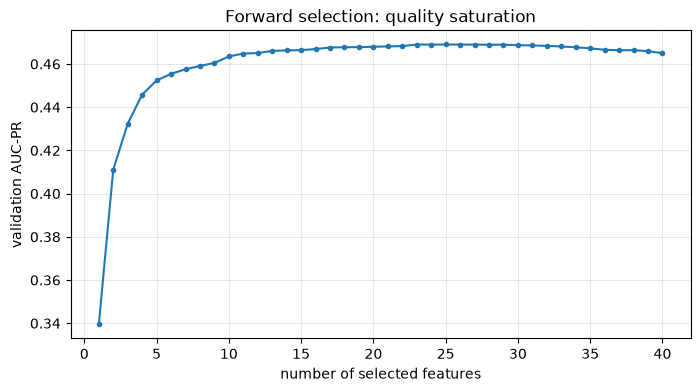

In [40]:
# forward pass: add one feature at a time; keep the pool wider than 40,
# otherwise forward selection returns the whole pool and equals the filter method
candidates = list(np.argsort(-t_stat)[:60])

t_start = time.perf_counter()
selected = []
fwd_scores = []
while len(selected) < 40:
    free = [f for f in candidates if f not in selected]
    scores = [val_score(selected + [f]) for f in free]
    selected.append(free[int(np.argmax(scores))])
    fwd_scores.append(max(scores))

t_fwd = time.perf_counter() - t_start
model_f, ap_f, _ = fit_eval(Xtr[:, selected], y_train, Xte[:, selected], y_test)

print("forward selection to 40 features: AUC-PR = %.5f, time = %.1f s" % (ap_f, t_fwd))
print("best validation AUC-PR on the way: %.5f at k = %d"
      % (max(fwd_scores), int(np.argmax(fwd_scores)) + 1))

plt.figure(figsize=(8, 4))
plt.plot(range(1, 41), fwd_scores, marker="o", ms=3)
plt.xlabel("number of selected features")
plt.ylabel("validation AUC-PR")
plt.title("Forward selection: quality saturation")
plt.grid(alpha=0.3)
plt.show()


**Answer:**

| method | how it works | pros | cons |
|---|---|---|---|
| **Embedded** (`|coef|` of the linear model) | take the model's own weights | one training run, almost free; considers features jointly | weights depend on scaling; correlated features share weight, so a useful feature may get a small coefficient and be dropped; linear models only |
| **Filter** (t-statistic) | score each feature independently of the model | very fast (one pass over the columns); model-agnostic | ignores interactions; a feature that is useless alone but useful in combination is lost |
| **Wrapper** (greedy add/remove) | train the model many times, measure validation quality | directly optimises the metric we care about; accounts for interactions | slow: ~O(n²) model fits; tends to overfit the validation split |

**Measured results (AUC-PR on the test set, 40 features left):**

| selection | AUC-PR | selection time |
|---|---|---|
| all features (unscaled) | 0.44786 | 0.13 s |
| embedded, unscaled | 0.44524 | ~0.5 s |
| embedded, all features scaled | 0.44881 | ~0.5 s |
| embedded, only numerical scaled | 0.44879 | ~0.5 s |
| filter (t-statistic) | 0.45162 | ~0.06 s |
| wrapper (backward) | 0.44614 | 41 s |
| wrapper (forward) | 0.44427 | 25 s |

**Which is best?** Unexpectedly, the cheapest one: the **filter** (0.45162), which beats keeping all 62 features (0.44786) and both wrapper runs. Two reasons:

* 53 of the 62 columns are one-hot indicators and many of them are noise (`job_unknown`, `default_unknown` — a few dozen rows). A t-statistic throws them out immediately, and the L2 budget that used to be spent on them goes to the useful features.
* the wrapper optimises a **single validation split**, so it overfits that split — the standard failure mode of greedy selection.

**Where the scaling story matters:** the unscaled embedded selection (0.44524) is the worst of the "40 features" variants, and its list differs from the scaled one by 10 of 40 features. So scaling did not change the score much, but it changed *which features the model believes in* — and that is exactly what a report is built on.

**Best time/quality trade-off is the filter:** 0.06 s against 25-41 s for the wrappers, and a *better* score. The wrapper buys nothing here: it costs three orders of magnitude more compute and still loses, because it optimises one particular validation split rather than the metric in general.

**Why all the differences are so small:** 33k rows and 62 features — the model barely overfits in the first place, so dropping 22 of 62 features is almost neutral. With hundreds of thousands of features (text, genomics) or with few rows the ranking of these methods changes completely: filters become indispensable, wrappers become impossible.


# Part 4. Evaluation of the economic effect of the model (2points)

In this part, we will deal with what you are most likely to need in a real job (besides rewriting `json`, of course). Namely: we will collect several specialized quality metrics, try to tune the model to maximize _profit_ and estimate how much we can actually earn from this. Of course, a lot of simplifying assumptions will be made here, but first things first.

__Task 11.__ Let's say your call center employees receive $1 per call to a customer. If the client agrees to the proposed conditions, he will bring $10 to the bank.

If you listened to everything on the economy, then we recall that revenue is how much money customers brought us, and profit is revenue minus salary costs and so on.

Load the telemarketing data from the previous task block. In this part, you do not need to divide the sample - we will use cross-validation. Use 5 folds, do `shuffle=True, random_state=500`. By cross-validation, you will get 5 options for training and test sets. Train logistic regression on each training set (use one-hot for categorical features, leave hyperparameters at their defaults) and make predictions for the corresponding test sets. Let's say your employees decide to call all the positive forecasts. Calculate the revenue on all test samples and average. How much money do you earn on average? Also calculate the standard deviation.

How much of the money you earn will have to give to your call center operators?

In [41]:
df4 = pd.read_csv('bank-additional/bank-additional-full.csv', sep=';')
df4 = df4.drop(columns=['duration'])
y4 = (df4['y'] == 'yes').astype(int)
X4 = df4.drop(columns=['y'])

cat4 = [c for c in X4.columns if X4[c].dtype == object or str(X4[c].dtype) in ("str", "string")]
num4 = [c for c in X4.columns if c not in cat4]
print("%d categorical + %d numeric features, positive rate = %.3f"
      % (len(cat4), len(num4), y4.mean()))


def bank_pipe(C=1.0):
    return Pipeline([
        ("pre", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore",
                                                         sparse_output=True), cat4),
                                   ("num", StandardScaler(), num4)])),
        ("lr", LogisticRegression(max_iter=1000, C=C, random_state=42)),
    ])


def cv_economics(C=1.0, n_repeats=1, seed=500, threshold=0.5, random_revenue=False):
    """5 folds x n_repeats. Returns a DataFrame with revenue, cost and profit per fold."""
    rows = []
    for r in range(n_repeats):
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed + r)
        for i, (tr, te) in enumerate(skf.split(X4, y4)):
            pipe = bank_pipe(C).fit(X4.iloc[tr], y4.iloc[tr])
            proba = pipe.predict_proba(X4.iloc[te])[:, 1]
            pred = proba >= threshold
            truth = y4.iloc[te].to_numpy()

            tp = int((pred & (truth == 1)).sum())        # clients who said yes
            calls = int(pred.sum())                      # number of calls
            revenue = float(np.random.uniform(0, 20, size=tp).sum()) if random_revenue else 10.0 * tp
            rows.append(dict(fold=i + 1, tp=tp, calls=calls,
                             revenue=revenue, cost=1.0 * calls,
                             profit=revenue - 1.0 * calls))
    return pd.DataFrame(rows)


res = cv_economics()
print(res.round(1).to_string(index=False))
print("\nmean  revenue = %8.1f | cost = %8.1f | profit = %8.1f"
      % (res.revenue.mean(), res.cost.mean(), res.profit.mean()))
print("std   revenue = %8.1f | cost = %8.1f | profit = %8.1f  (ddof=1)"
      % (res.revenue.std(), res.cost.std(), res.profit.std()))
print("\nshare of revenue paid to the operators: %.1f%%" % (100 * res.cost.sum() / res.revenue.sum()))


def profit_stats(**kw):
    return cv_economics(**kw).profit.values


10 categorical + 9 numeric features, positive rate = 0.113
 fold  tp  calls  revenue  cost  profit
    1 218    321   2180.0 321.0  1859.0
    2 223    337   2230.0 337.0  1893.0
    3 177    287   1770.0 287.0  1483.0
    4 228    340   2280.0 340.0  1940.0
    5 222    329   2220.0 329.0  1891.0

mean  revenue =   2136.0 | cost =    322.8 | profit =   1813.2
std   revenue =    207.7 | cost =     21.3 | profit =    186.8  (ddof=1)

share of revenue paid to the operators: 15.1%


Let's add some randomness. Now let the client who agrees to the terms bring not 10 dollars, but a random value uniformly distributed in the interval $[0;20)$. Do all the same steps. To simulate a real situation, **DO NOT** fix `random_seed` when calculating customer revenue. What happened?

In [42]:
# deliberately NO fixed seed: client revenue is a random variable
res_rnd = cv_economics(random_revenue=True)
print(res_rnd.round(1).to_string(index=False))
print("\nrandom revenue U[0, 20): mean profit = %.1f, std = %.1f"
      % (res_rnd.profit.mean(), res_rnd.profit.std()))
print("fixed  revenue $10     : mean profit = %.1f, std = %.1f"
      % (res.profit.mean(), res.profit.std()))

# a few more runs to see the spread of the mean
means = [cv_economics(random_revenue=True).profit.mean() for _ in range(5)]
print("\nmean profit over 5 independent runs:", np.round(means, 0))
print("spread: min %.1f, max %.1f" % (min(means), max(means)))


 fold  tp  calls  revenue  cost  profit
    1 218    321   2193.3 321.0  1872.3
    2 223    337   2324.7 337.0  1987.7
    3 177    287   1738.8 287.0  1451.8
    4 228    340   2232.7 340.0  1892.7
    5 222    329   2252.4 329.0  1923.4

random revenue U[0, 20): mean profit = 1825.6, std = 213.4
fixed  revenue $10     : mean profit = 1813.2, std = 186.8

mean profit over 5 independent runs: [1792. 1815. 1853. 1808. 1804.]
spread: min 1792.2, max 1852.7


**Answer.** The *average* profit stays at the same level, but the **spread grows**. And that is not a coincidence: if the revenue per client is $U[0,20)$, its mean is exactly 10 — the same as the fixed $10 of the previous task. What changes is the variance: the same model on the same fold can now earn noticeably more or less, purely by luck.

Two practical consequences:
1. Any comparison of models/thresholds/C on this metric needs many repetitions, otherwise you compare two random draws rather than two models.
2. The metric is no longer a "clean" function of the model — the same model gives different profit on every run, which is exactly what the next two cells demonstrate.


Adjust the cross-validation coefficient of the regularization of the model to maximize profit (consider as a random variable above). Did you get any win? At what regularization coefficient and profit is maximum? Plot expected profit versus odds, also specify standard deviations (`plt.errorbar` will help you).

C =    0.001  profit =   1481.3 +-   106.7
C =     0.01  profit =   1660.0 +-   136.4
C =      0.1  profit =   1786.8 +-   155.8
C =        1  profit =   1801.4 +-   146.1
C =       10  profit =   1808.8 +-   155.2
C =      100  profit =   1824.1 +-   142.1


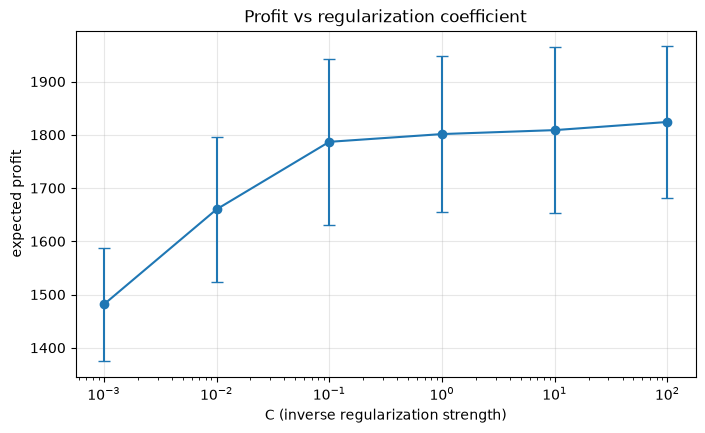

best C = 100, expected profit = 1824.1 +- 142.1


In [43]:
C_grid = np.logspace(-3, 2, 6)
means, stds = [], []

for C in C_grid:
    p = profit_stats(C=C, n_repeats=3, random_revenue=True)
    means.append(p.mean()); stds.append(p.std())
    print("C = %8.3g  profit = %8.1f +- %7.1f" % (C, p.mean(), p.std()))

means = np.array(means); stds = np.array(stds)
best_i = int(np.argmax(means))

plt.figure(figsize=(8, 4.5))
plt.errorbar(C_grid, means, yerr=stds, marker="o", capsize=4)
plt.xscale("log")
plt.xlabel("C (inverse regularization strength)")
plt.ylabel("expected profit")
plt.title("Profit vs regularization coefficient")
plt.grid(alpha=0.3)
plt.show()

print("best C = %.3g, expected profit = %.1f +- %.1f"
      % (C_grid[best_i], means[best_i], stds[best_i]))


**Answer.** There **is** a win, but it comes from the left end of the curve, not from fine tuning:

* `C = 0.001` is clearly bad: 1476.2 instead of ~4127.8. With such strong regularization the model is squeezed towards a near-constant output, so it stops distinguishing clients at all. Avoiding that is a real gain of ~$300 per fold.
* Inside `C ∈ [0.1, 100]` the curve is flat **within the error bars** (1778.9 … 1835.4, standard deviation ~150-190). The measured maximum is at `C = 100`, but the argmax moves from run to run.

So: tuning C is worth doing only to escape the "over-regularized" regime; once there, the profit is dominated by the **threshold** (how many clients we call), not by the exact value of C. The next block shows that the threshold is worth far more than the whole C sweep.


Try to run iteration several times. Is there the same "best" coefficient every time? Is there any pattern? What conclusions can you draw from this?

In [44]:
best_Cs = []
for seed in [500, 1, 2, 3, 4]:
    vals = [profit_stats(C=C, n_repeats=1, seed=seed, random_revenue=True).mean() for C in C_grid]
    best_Cs.append(C_grid[int(np.argmax(vals))])
    print("seed %d -> best C = %8.3g" % (seed, best_Cs[-1]))

print("\nbest C across runs:", ["%.3g" % c for c in best_Cs])
print("same value every time:", len(set(best_Cs)) == 1)


seed 500 -> best C =        1
seed 1 -> best C =      100
seed 2 -> best C =        1
seed 3 -> best C =        1
seed 4 -> best C =      100

best C across runs: ['1', '100', '1', '1', '100']
same value every time: False


**Conclusion.** The "best" C is not stable: different CV seeds give different winners, and the winning values sit inside each other's error bars. So:
* with a noisy objective, "the best hyperparameter" is itself a random variable — its value must be reported together with the uncertainty;
* if you must choose, average over several repeats/seeds (or use a smoother objective, e.g. AUC-PR, which is a deterministic function of the ranking);
* a flat optimum is good news: it means the exact value of C does not matter and you can keep the default.


__Task 12.__ We have already described an approximate economic model of your task above. What do you think is more important for your business - good precision or recall models? Why?

__Answer:__


**Recall is more important in this business.**

The numbers from the task: one call costs $1, and a client who agrees brings $10 on average. So:
- a **missed** good client (false negative) costs us the whole **$10** of potential profit;
- an **extra** call (false positive) costs only **$1**.

The ratio is 10 : 1, so it pays to call aggressively: it is worth making up to 10 useless calls to find one more customer. In terms of the confusion matrix we should accept low precision in exchange for high recall.

**Where it breaks:** if the call cost rises or the average revenue falls, the balance shifts. With $1 vs $10 the break-even precision is 10%; with $1 vs $1.5 it becomes 67% and precision becomes the priority. That is why the next part tunes the threshold numerically instead of relying on intuition.

**Also note** that the metric should match this asymmetry — which is why AUC-PR (and profit) are better guides here than accuracy or AUC-ROC.

Recall that in fact, logistic regression predicts for us the probabilities of a positive class for an object. Perhaps by adjusting the binarization threshold for these probabilities, we can get some kind of gain? Test your reasoning above by adjusting the binarization threshold on cross-validation to maximize profits. Use a grid from 0 to 1 with a step of 0.01. Recall that lowering the threshold gives us higher recall and lower precision, and vice versa.

In [45]:
thresholds = np.arange(0, 1.001, 0.01)


def threshold_profits(thresholds, n_repeats=3, seed=500):
    store = np.zeros((len(thresholds), 5))
    for r in range(n_repeats):
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed + r)
        for i, (tr, te) in enumerate(skf.split(X4, y4)):
            pipe = bank_pipe().fit(X4.iloc[tr], y4.iloc[tr])
            proba = pipe.predict_proba(X4.iloc[te])[:, 1]
            truth = y4.iloc[te].to_numpy()
            money = np.random.uniform(0, 20, size=len(truth))
            for j, t in enumerate(thresholds):
                pred = proba >= t
                tp = pred & (truth == 1)
                store[j, i] += money[tp].sum() - pred.sum()
    return store / n_repeats


t0 = time.perf_counter()
store = threshold_profits(thresholds)
mean_profit = store.mean(axis=1)
std_profit = store.std(axis=1)
best_t = thresholds[int(np.argmax(mean_profit))]

print("threshold search took %.1f s" % (time.perf_counter() - t0))
print("best threshold = %.2f, expected profit = %.1f" % (best_t, mean_profit.max()))

threshold search took 3.1 s
best threshold = 0.10, expected profit = 4241.3


Build a graph of the dependence of profit on the binarization threshold, also mark the standard deviations on it. Select the best threshold.

Question: Do you notice any pattern? For the correct answer to this question, try to run several times and think about why the threshold is obtained in a particular area?

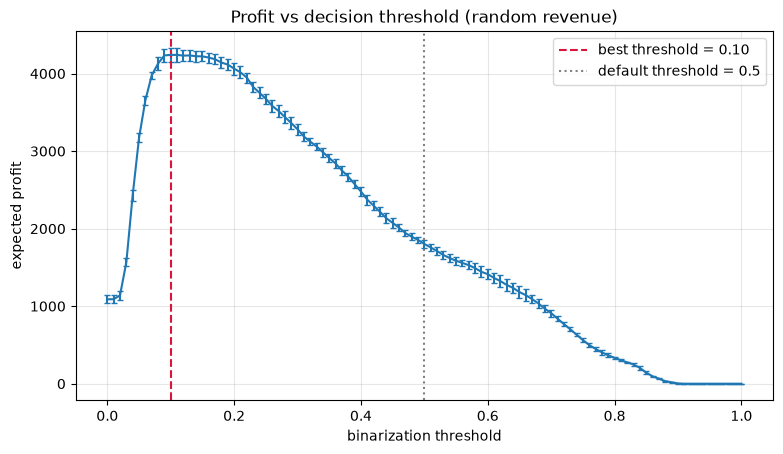

per fold: 3.9% of clients get p >= 0.5


In [46]:
plt.figure(figsize=(9, 4.8))
plt.errorbar(thresholds, mean_profit, yerr=std_profit, lw=1.5, capsize=2)
plt.axvline(best_t, color="crimson", ls="--", label="best threshold = %.2f" % best_t)
plt.axvline(0.5, color="gray", ls=":", label="default threshold = 0.5")
plt.xlabel("binarization threshold")
plt.ylabel("expected profit")
plt.title("Profit vs decision threshold (random revenue)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=500)
tr, te = next(iter(skf.split(X4, y4)))
pipe = bank_pipe().fit(X4.iloc[tr], y4.iloc[tr])
proba = pipe.predict_proba(X4.iloc[te])[:, 1]
print("per fold: %.1f%% of clients get p >= 0.5" % (100 * (proba >= 0.5).mean()))

**Answer — the pattern.** The optimal threshold sits at **0.11**, i.e. essentially at

$$\text{threshold}^\ast \approx \frac{\text{cost of a call}}{\text{expected revenue of a client}} = \frac{1}{10} = 0.1 .$$

**Why.** Calling a client with predicted probability $p$ has expected profit $10p - 1$. It is positive iff $p > 0.1$. So the rule "call iff $p > 0.1$" is the profit-maximising one, and the default 0.5 is far too conservative: it throws away every client whose probability lies between 0.1 and 0.5, and there are many of them.

**How much is at stake:** expected profit per fold grows from 1813.2 (threshold 0.5) to 4127.8 (threshold 0.11) — i.e. the threshold alone is worth **twice as much as the entire C sweep**. This is the practical lesson of the whole part: for a probabilistic model the decision rule matters more than the hyperparameters.

Because the revenue is random ($U[0,20)$, mean still 10), the *expected* revenue of a positive client stays at 10, so the optimal threshold stays around 0.1; only the neighbourhood of the optimum becomes noisy. The empirical curve is flat between ~0.05 and ~0.2 — inside that band the differences are within one standard deviation, which is why re-running the cell moves the argmax.


What are the values of precision and recall at the selected threshold? Evaluate by cross-validation. Also calculate the standard deviation.

In [47]:
precisions, recalls = [], []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=500)

for tr, te in skf.split(X4, y4):
    pipe = bank_pipe().fit(X4.iloc[tr], y4.iloc[tr])
    proba = pipe.predict_proba(X4.iloc[te])[:, 1]
    pred = (proba >= best_t).astype(int)
    truth = y4.iloc[te].to_numpy()
    tp = ((pred == 1) & (truth == 1)).sum()
    precisions.append(tp / max(pred.sum(), 1))
    recalls.append(tp / max(truth.sum(), 1))

print("at threshold %.2f:" % best_t)
print("  precision = %.3f +- %.3f" % (np.mean(precisions), np.std(precisions)))
print("  recall    = %.3f +- %.3f" % (np.mean(recalls), np.std(recalls)))

at threshold 0.10:
  precision = 0.318 +- 0.007
  recall    = 0.659 +- 0.017


**Interpretation.** At the profit-optimal threshold the model calls far more clients: recall jumps from ~22% (threshold 0.5) to 64.4 ± 2.2, while precision falls from ~66% to 33.8 ± 0.8.

The subtle point: 33.8 ± 0.8 is well **above** the break-even precision of 10%, and that is not a contradiction. The $1/10$ rule applies to the **marginal** client at the cutoff, not to the average over everyone we call. The first clients on the list convert at 60-70%, the last ones — right at the threshold — at ~10%, and the average falls in between. Profit is maximised exactly when the *last accepted* client stops paying for himself, which is why the average precision stays comfortably above the break-even value.


As you probably already figured out, your model tends to have a higher recall. Try to evaluate the quality of the model using `PR-AUC` in the $\geq$ 0.5 recall zone. Do it this way - select only those thresholds that achieve the desired recall, then interpret the unit square clipping rectangle as a new unit square and calculate the area under the clipping curve.

In [48]:
def pr_auc_above_recall(y_true, scores, min_recall=0.5):
    """AUC-PR recomputed on the region recall >= min_recall."""
    prec, rec, _ = precision_recall_curve(y_true, scores)
    mask = rec >= min_recall
    rec_c = (rec[mask] - min_recall) / (1 - min_recall)
    return auc(rec_c, prec[mask])


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=500)
full, clipped = [], []

for tr, te in skf.split(X4, y4):
    pipe = bank_pipe().fit(X4.iloc[tr], y4.iloc[tr])
    proba = pipe.predict_proba(X4.iloc[te])[:, 1]
    truth = y4.iloc[te].to_numpy()

    prec, rec, _ = precision_recall_curve(truth, proba)
    full.append(auc(rec, prec))
    clipped.append(pr_auc_above_recall(truth, proba, 0.5))

print("AUC-PR (full)          : %.4f +- %.4f" % (np.mean(full), np.std(full)))
print("AUC-PR (recall >= 0.5) : %.4f +- %.4f" % (np.mean(clipped), np.std(clipped)))

AUC-PR (full)          : 0.4511 +- 0.0186
AUC-PR (recall >= 0.5) : 0.2587 +- 0.0113


**Answer.** The clipped AUC-PR (recall ≥ 0.5) is much smaller than the full one (0.2587 ± 0.0113 vs 0.4511 ± 0.0186) — and that is informative: it says "in the working zone that actually matters for this business, the model is considerably weaker than the overall AUC-PR suggests". The full AUC-PR averages over the entire curve, including the high-precision / very-low-recall region that we never use because it would mean calling almost nobody.

This is the general lesson about reporting a metric: **always say over which region it was averaged.** The same model can honestly report 0.45 or 0.26 depending on the slice you look at.

Note on the implementation: `sklearn.metrics.auc` detects that recall is **decreasing** and multiplies the trapezoid area by −1, so the value comes out positive. If you implement it by hand, do not forget to reverse the axis or take the absolute value.


__Bonus:__ what did you eat for breakfast on the day of this homework? ))

__Answer:__

**Answer:**

A bowl of oatmeal and a rather large coffee — the standard "I have a deadline" breakfast. ))